# CAI 421 — Kaggle Edition: External RED-CNN + RiskMapUNet v2
**Adapted from your uploaded Colab notebook.** This is a focused, executable version of the **current** pipeline, not the discontinued synthetic-lesion or self-trained RED-CNN experiments.

**Before running:** attach a **private** Kaggle Dataset containing `CAI421_processed` (including `pairs_raw_hu`, `pairs`, `student1_handoff/patient_splits.json`, `weak_lesion_masks`, and `alteration_pseudo_labels_external`). Also attach the external `RED-CNN/networks.py` and `REDCNN_100000iter.ckpt` checkpoint. The existing `best_external.pt` is optional if you plan to train.

**Execution:** Run setup → file audit → RED-CNN loading → report QA → model definition → volume loader → training **or** load an existing checkpoint → validation/test evaluation → report export. Optional regeneration cells are clearly labeled. All output files go to `/kaggle/working/CAI421_results` (not read-only `/kaggle/input`).

**Research caution:** Weak candidate lesion circles and reference-error pseudo-labels are not expert-confirmed tumor boundaries or clinical damage. The provisional 1% classification cutoff is not clinically calibrated.

ACCEPT AND REJECT THAT HAPPENED TO BOTH THE 88 LESIONS AND 55 LESIONS - part *

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

root = Path("/kaggle/working/CAI421_processed")
folder = Path("/kaggle/working/liver_review")
folder.mkdir(parents=True, exist_ok=True)

file = folder / "automatic_liver_review.csv"
accepted_file = folder / "accepted_liver_slices.csv"
keys = ["case_id", "lesion_id"]

data = pd.read_csv(root / "student1_handoff/final_lesion_review.csv")
source = pd.read_csv(root / "student1_handoff/annotations_source_audit.csv")

review = data.loc[data.effective_status.eq("verified_auto"), keys].merge(
    source[keys + ["slice_no"]], on=keys, validate="one_to_one"
)

columns = keys + ["suggested_slice_index", "confirmed_slice_index", "decision"]
saved = pd.read_csv(file) if file.exists() else pd.DataFrame(columns=columns)

# Preserve previous decisions and recover missing suggested slices
if "suggested_slice_index" not in saved:
    saved = saved.merge(source[keys + ["slice_no"]], on=keys, how="left")
    saved = saved.rename(columns={"slice_no": "suggested_slice_index"})
    saved.to_csv(file, index=False)

done = set(map(tuple, saved[keys].to_numpy()))
review = review[
    ~review[keys].apply(tuple, axis=1).isin(done)
].reset_index(drop=True)

status = widgets.HTML()
note = widgets.HTML()
entry = widgets.Text(
    description="Slices:",
    placeholder="120,121,122",
    layout={"width": "300px"}
)
accept = widgets.Button(description="Accept", button_style="success")
reject = widgets.Button(description="Reject All", button_style="danger")
output = widgets.Output()

position = 0

def show():
    global choices

    with output:
        clear_output(wait=True)

        if position >= len(review):
            status.value = "<b>Review complete!</b>"
            print("Saved:", file)
            return

        row = review.iloc[position]

        with np.load(root / "pairs" / f"{row.case_id}.npz") as f:
            low, full = f["low"], f["full"]

        with np.load(root / "denoised_red_cnn" / f"{row.case_id}.npz") as f:
            red = f["denoised"]

        if low.shape != red.shape or low.shape != full.shape:
            raise ValueError(f"Shape mismatch: {row.case_id}")

        z = int(row.slice_no)
        choices = [i for i in (z - 1, z, z + 1) if 0 <= i < len(low)]

        status.value = (
            f"<b>{position + 1}/{len(review)} remaining — "
            f"{row.case_id} | Candidate {row.lesion_id}</b>"
        )
        entry.value = ""
        note.value = ""

        fig, axes = plt.subplots(
            len(choices), 3,
            figsize=(12, 3.5 * len(choices)),
            squeeze=False
        )

        for i, z in enumerate(choices):
            for ax, image, title in zip(
                axes[i],
                (low, red, full),
                ("Low-dose", "RED-CNN", "Full-dose")
            ):
                ax.imshow(image[z], cmap="gray")
                ax.set_title(f"{title} | Slice {z}")
                ax.axis("off")

        plt.tight_layout()
        plt.show()

def save(decision, slices):
    global position, saved

    if position >= len(review):
        return

    row = review.iloc[position]
    rows = [{
        "case_id": row.case_id,
        "lesion_id": row.lesion_id,
        "suggested_slice_index": int(row.slice_no),
        "confirmed_slice_index": z,
        "decision": decision
    } for z in slices]

    saved = pd.concat([saved, pd.DataFrame(rows)], ignore_index=True)
    saved.to_csv(file, index=False)

    saved.loc[
        saved.decision.eq("accept"),
        ["case_id", "confirmed_slice_index"]
    ].dropna().drop_duplicates().to_csv(accepted_file, index=False)

    position += 1
    show()

def on_accept(_):
    try:
        slices = sorted({int(x.strip()) for x in entry.value.split(",")})
        if not slices or not set(slices).issubset(choices):
            raise ValueError
    except ValueError:
        note.value = f"<span style='color:red'>Choose from {choices}</span>"
        return

    save("accept", slices)

accept.on_click(on_accept)
reject.on_click(lambda _: save("reject", [None]))

print("Total automatic candidates:", len(data[data.effective_status.eq("verified_auto")]))
print("Previously reviewed:", len(done))
print("Remaining:", len(review))
print("Folder:", folder)

display(status, output, entry, widgets.HBox([accept, reject]), note)
show()

Total automatic candidates: 55
Previously reviewed: 55
Remaining: 0
Folder: /kaggle/working/liver_review


HTML(value='')

Output()

Text(value='', description='Slices:', layout=Layout(width='300px'), placeholder='120,121,122')

HTML(value='')

> samples of how the rejection and accept happened (we chose depending on the liver appearance)

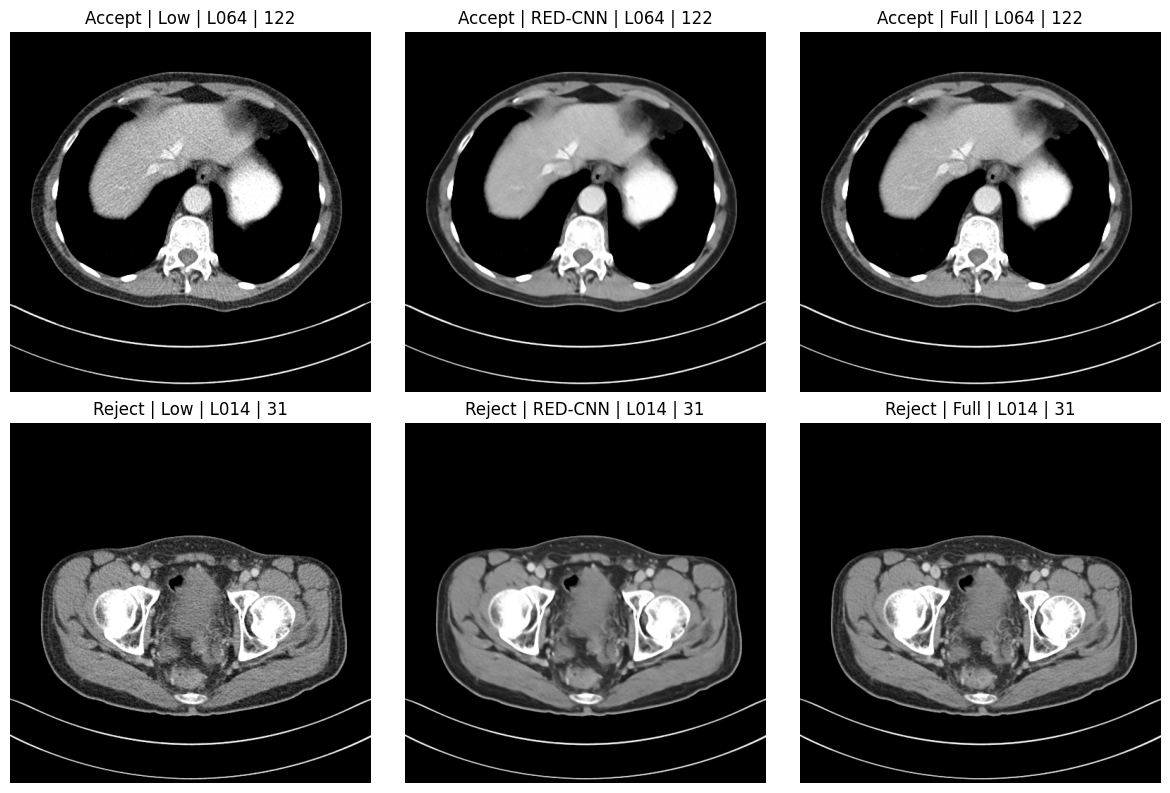

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

root = "/kaggle/working/CAI421_processed"
df = pd.read_csv("/kaggle/working/liver_review/automatic_liver_review.csv")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, decision in enumerate(["accept", "reject"]):
    row = df[df.decision.eq(decision)].iloc[0]
    z = int(row.confirmed_slice_index if decision == "accept" else row.suggested_slice_index)

    with np.load(f"{root}/pairs/{row.case_id}.npz") as f:
        images = [f["low"][z], f["full"][z]]
    with np.load(f"{root}/denoised_red_cnn/{row.case_id}.npz") as f:
        images.insert(1, f["denoised"][z])

    for ax, image, name in zip(axes[i], images, ["Low", "RED-CNN", "Full"]):
        ax.imshow(image, cmap="gray")
        ax.set_title(f"{decision.title()} | {name} | {row.case_id} | {z}")
        ax.axis("off")

plt.tight_layout()
plt.show()

IMPORTANT- must run to deal with data

In [2]:
from pathlib import Path
import shutil
import json
import torch

# All six extracted folders
INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working/CAI421_results")
WORK.mkdir(parents=True, exist_ok=True)

# One combined project folder
ROOT = Path("/kaggle/working/CAI421_processed")
ROOT.mkdir(parents=True, exist_ok=True)

# Find all six project folders
source_roots = sorted(
    p for p in INPUT.rglob("CAI421_processed")
    if p.is_dir()
)

print("Source folders found:", len(source_roots))

assert len(source_roots) == 6, (
    f"Expected 6 folders, found {len(source_roots)}"
)

# Merge files from all six folders
for source in source_roots:
    print("Merging:", source.parent.name)

    for file in source.rglob("*"):
        if not file.is_file():
            continue

        relative_path = file.relative_to(source)
        destination = ROOT / relative_path
        destination.parent.mkdir(parents=True, exist_ok=True)

        if not destination.exists():
            shutil.copy2(file, destination)

print("\nMerge completed!")

Source folders found: 6
Merging: CAI421_processed-20261112T185000Z-1-001
Merging: CAI421_processed-20261112T185000Z-1-002
Merging: CAI421_processed-20261112T185000Z-1-003
Merging: CAI421_processed-20261112T185000Z-1-004
Merging: CAI421_processed-20261112T185000Z-1-005
Merging: CAI421_processed-20261112T185000Z-1-006

Merge completed!


In [18]:
from pathlib import Path
import pandas as pd

ROOT = Path("/kaggle/working/CAI421_processed")
DATA = ROOT / "student1_handoff"
REPORT = Path("/kaggle/working/dataset_audit")
REPORT.mkdir(parents=True, exist_ok=True)

manual = pd.read_csv(DATA / "manual_slice_review_FINAL_20261029_1317.csv")
source = pd.read_csv(DATA / "annotations_source_audit.csv")

print("Manual decisions:")
print(manual["decision"].value_counts())

print("\nManual review columns:")
print(manual.columns.tolist())

print("\nSource columns:")
print(source.columns.tolist())

approved = manual[manual["decision"].eq("approve")].copy()

print("\nApproved:", len(approved))
display(approved.head())

Manual decisions:
decision
reject     48
approve    40
Name: count, dtype: int64

Manual review columns:
['case_id', 'lesion_id', 'snapshot', 'suggested_index', 'decision', 'confirmed_slice_index', 'reviewer', 'evidence_notes']

Source columns:
['case_id', 'lesion_id', 'diagnosis_code', 'diagnosis', 'manufacturer', 'series_role', 'location_raw', 'snapshot', 'parsed', 'radius_px', 'x', 'y', 'slice_no', 'usable']

Approved: 40


,case_id,lesion_id,snapshot,suggested_index,decision,confirmed_slice_index,reviewer,evidence_notes
0,L004,1,L004_1.jpg,73,approve,74.0,rama,"Liver outline, spine, stomach air, and vessels..."
1,L004,2,L004_2.jpg,77,approve,77.0,rama,"Spine, liver outline, stomach air, and vessels..."
2,L004,3,L004_3.jpg,44,approve,44.0,rama,"Spine, kidneys, liver outline, and abdominal v..."
3,L004,4,L004_4.jpg,72,approve,72.0,rama,"Liver outline, spine, stomach air, and hepatic..."
5,L014,1,L014_1.jpg,119,approve,119.0,rama,"Liver outline, spine, stomach air, and vessels..."


now all accepted data is saved in a file

In [14]:
from pathlib import Path
import pandas as pd

root = Path("/kaggle/working/CAI421_processed")
folder = Path("/kaggle/working/liver_review")

manual = pd.read_csv(root / "student1_handoff/manual_slice_review_FINAL_20261029_1317.csv")
auto = pd.read_csv(folder / "automatic_liver_review.csv")

manual = manual.loc[manual.decision.eq("approve"),
                    ["case_id", "confirmed_slice_index"]]
auto = auto.loc[auto.decision.eq("accept"),
                ["case_id", "confirmed_slice_index"]]

combined = pd.concat([manual, auto], ignore_index=True)
combined = combined.dropna().drop_duplicates().reset_index(drop=True)
combined["confirmed_slice_index"] = combined["confirmed_slice_index"].astype(int)

combined.to_csv(folder / "final_liver_slices.csv", index=False)

print("Manual approved:", len(manual))
print("Automatic accepted:", len(auto))
print("Unique combined slices:", len(combined))
print("Patients:", combined.case_id.nunique())
print("Saved:", folder / "final_liver_slices.csv")

Manual approved: 40
Automatic accepted: 4
Unique combined slices: 41
Patients: 16
Saved: /kaggle/working/liver_review/final_liver_slices.csv


inspecting how the mask look like on the accepted samples using a tool called totalsegmentor  

In [24]:
import sys
import subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "TotalSegmentator"], check=True)
from totalsegmentator.python_api import totalsegmentator
print("TotalSegmentator installed successfully")

TotalSegmentator installed successfully


In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import torch
from scipy.ndimage import label
from nibabel.processing import resample_from_to
from totalsegmentator.python_api import totalsegmentator

root = Path("/kaggle/working/CAI421_processed")
out = root / "totalseg_final"
out.mkdir(exist_ok=True)

df = pd.read_csv("/kaggle/working/liver_review/final_liver_slices.csv")
records = []

for case, group in df.groupby("case_id"):
    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        hu = f["full_hu"].astype(np.float32)
        pos = f["positions"].astype(float)

    with np.load(root / "pairs" / f"{case}.npz") as f:
        xy = f["pixel_spacing"].astype(float)

    delta = np.diff(pos, axis=0)
    dz = float(np.median(delta[:, 2]))

    assert hu.shape[0] == len(pos)
    assert hu.shape[1:] == (512, 512)
    assert len(delta) > 0 and abs(dz) > 0.1
    assert np.isfinite(hu).all() and np.isfinite(pos).all()
    assert np.all(xy > 0) and np.isfinite(xy).all()
    assert np.max(abs(delta[:, :2])) < 0.1
    assert np.max(abs(delta[:, 2] - dz)) < 0.1

    affine = np.array([
        [-xy[1], 0, 0, -pos[0, 0]],
        [0, -xy[0], 0, -pos[0, 1]],
        [0, 0, dz, pos[0, 2]],
        [0, 0, 0, 1]
    ])

    nii = nib.Nifti1Image(hu.transpose(2, 1, 0), affine)
    result = totalsegmentator(
        nii, task="total", roi_subset=["liver"],
        device="gpu" if torch.cuda.is_available() else "cpu",
        quiet=True
    )
    if isinstance(result, dict):
        result = result["liver"]

    if result.shape != nii.shape or not np.allclose(result.affine, nii.affine):
        result = resample_from_to(result, nii, order=0)

    mask = (np.asarray(result.dataobj) > 0).transpose(2, 1, 0)
    components, _ = label(mask, structure=np.ones((3, 3, 3)))
    sizes = np.bincount(components.ravel())
    sizes[0] = 0
    mask = components == sizes.argmax()

    z = sorted(group.confirmed_slice_index.astype(int).unique())
    assert mask.shape == hu.shape and min(z) >= 0 and max(z) < len(mask)

    selected = mask[z].astype(np.uint8)
    np.savez_compressed(
        out / f"{case}.npz",
        slices=np.array(z),
        mask=selected
    )

    for index, pixels in zip(z, selected.sum(axis=(1, 2))):
        records.append([case, index, int(pixels)])

    print(f"{case}: {len(z)} slices saved")

qc = pd.DataFrame(records, columns=["case_id", "slice", "liver_pixels"])
qc["has_liver"] = qc.liver_pixels > 0
qc.to_csv(out / "mask_qc.csv", index=False)

print("\nTotal slices:", len(qc))
print("With liver:", qc.has_liver.sum())
print("Without liver:", (~qc.has_liver).sum())
print("Saved:", out)

TotalSegmentator sends anonymous usage statistics. If you want to disable it check the documentation.


Downloading: 100%|██████████| 234M/234M [00:02<00:00, 99.8MB/s] 


Download finished. Extracting...


Downloading: 100%|██████████| 234M/234M [00:02<00:00, 102MB/s]  


Download finished. Extracting...


Downloading: 100%|██████████| 234M/234M [00:01<00:00, 119MB/s]  


... (5 outputs left out)

Downloading: 100%|██████████| 135M/135M [00:01<00:00, 98.4MB/s] 


Download finished. Extracting...


get_mempolicy: Operation not permitted


L004: 4 slices saved
L014: 1 slices saved
L033: 1 slices saved
L057: 2 slices saved
L058: 1 slices saved
L064: 6 slices saved
L075: 2 slices saved
L077: 2 slices saved
L081: 6 slices saved
L110: 2 slices saved
L114: 1 slices saved
L123: 2 slices saved
L131: 4 slices saved
L160: 2 slices saved
L219: 1 slices saved
L220: 4 slices saved

Total slices: 41
With liver: 41
Without liver: 0
Saved: /kaggle/working/CAI421_processed/totalseg_final


we will use the external redcnn - which aims to denois the ct images- on our 41 samples

In [22]:
from pathlib import Path
import subprocess, sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

root = Path("/kaggle/working/CAI421_processed")
repo = Path("/kaggle/working/RED-CNN")
out = root / "external_redcnn_final"
out.mkdir(exist_ok=True)

if not (repo / "networks.py").exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/SSinyu/RED-CNN.git", str(repo)
    ], check=True)

ckpts = list(repo.rglob("REDCNN_100000iter.ckpt"))
ckpts += list(Path("/kaggle/input").rglob("REDCNN_100000iter.ckpt"))
if not ckpts:
    raise FileNotFoundError("External pretrained checkpoint not found.")

sys.path.insert(0, str(repo))
nn.Conv2D, nn.ConvTranspose2D = nn.Conv2d, nn.ConvTranspose2d
from networks import RED_CNN

device = "cuda" if torch.cuda.is_available() else "cpu"
model = RED_CNN().to(device)
model.load_state_dict(
    torch.load(ckpts[0], map_location="cpu", weights_only=True),
    strict=True
)
model.eval()

df = pd.read_csv("/kaggle/working/liver_review/final_liver_slices.csv")
records = []

for case, group in df.groupby("case_id"):
    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        keys = list(f.files)
        candidates = [k for k in ("low_hu", "low", "ldct") if k in keys]
        if not candidates:
            raise KeyError(f"{case}: unknown raw-HU keys {keys}")
        low = f[candidates[0]]

    z = sorted(group.confirmed_slice_index.astype(int).unique())
    assert low.ndim == 3 and max(z) < len(low), f"Invalid slices: {case}"

    images = low[z].astype(np.float32)
    result = np.empty_like(images)

    with torch.inference_mode():
        for start in range(0, len(images), 4):
            batch = (images[start:start + 4] + 1024) / 4096
            batch = torch.from_numpy(batch[:, None]).to(device)
            pred = model(batch)[:, 0].cpu().numpy()
            result[start:start + 4] = pred * 4096 - 1024

    assert np.isfinite(result).all(), f"Invalid output: {case}"
    np.savez_compressed(out / f"{case}.npz",
                        slices=np.array(z), denoised_hu=result)
    records.extend((case, int(s)) for s in z)
    print(f"{case}: {len(z)} slices saved")

pd.DataFrame(records, columns=["case_id", "slice"]).to_csv(
    out / "processed_slices.csv", index=False
)

print(f"\nCompleted: {len(records)} slices")
print("Checkpoint:", ckpts[0])
print("Saved:", out)

Cloning into '/kaggle/working/RED-CNN'...


L004: 4 slices saved
L014: 1 slices saved
L033: 1 slices saved
L057: 2 slices saved
L058: 1 slices saved
L064: 6 slices saved
L075: 2 slices saved
L077: 2 slices saved
L081: 6 slices saved
L110: 2 slices saved
L114: 1 slices saved
L123: 2 slices saved
L131: 4 slices saved
L160: 2 slices saved
L219: 1 slices saved
L220: 4 slices saved

Completed: 41 slices
Checkpoint: /kaggle/working/RED-CNN/save/REDCNN_100000iter.ckpt
Saved: /kaggle/working/CAI421_processed/external_redcnn_final


before proceeding we need to check the normalization if it suits the external repository Otherwise, the model might receive images with the wrong intensity scale, leading to inaccurate results.
as a result the RED-CNN normalization formula, (HU + 1024) / 4096, matches the repository’s default HU range of −1024 to 3072. This supports the correctness of our preprocessing and denormalization

In [35]:
from pathlib import Path

repo = Path("/kaggle/working/RED-CNN")

for name in ["main.py", "loader.py", "solver.py"]:
    path = repo / name
    if not path.exists():
        continue

    lines = path.read_text(errors="ignore").splitlines()
    print(f"\n--- {name} ---")

    for i, line in enumerate(lines):
        if any(k in line.lower() for k in
               ["norm_range", "trunc_min", "trunc_max", "normalize", "denormalize"]):
            start, end = max(0, i-2), min(len(lines), i+4)
            print("\n".join(f"{j+1}: {lines[j]}" for j in range(start, end)))
            print()


--- main.py ---
47:     parser.add_argument('--result_fig', type=bool, default=True)
48: 
49:     parser.add_argument('--norm_range_min', type=float, default=-1024.0)
50:     parser.add_argument('--norm_range_max', type=float, default=3072.0)
51:     parser.add_argument('--trunc_min', type=float, default=-160.0)
52:     parser.add_argument('--trunc_max', type=float, default=240.0)

48: 
49:     parser.add_argument('--norm_range_min', type=float, default=-1024.0)
50:     parser.add_argument('--norm_range_max', type=float, default=3072.0)
51:     parser.add_argument('--trunc_min', type=float, default=-160.0)
52:     parser.add_argument('--trunc_max', type=float, default=240.0)
53: 

49:     parser.add_argument('--norm_range_min', type=float, default=-1024.0)
50:     parser.add_argument('--norm_range_max', type=float, default=3072.0)
51:     parser.add_argument('--trunc_min', type=float, default=-160.0)
52:     parser.add_argument('--trunc_max', type=float, default=240.0)
53: 
54:     pa

We only want to study changes inside the liver by looking through the liver mask
Delta = |D-F|-|L-F|
1: Liver pixel where RED-CNN increased reference error by more than 4 HU.
0: Everything else.
as a result we got On average, 17.72% of the liver pixels in each selected slice were labeled as having an increase in error greater than 4 HU after RED-CNN denoising.

In [28]:
from pathlib import Path
import numpy as np
import pandas as pd

root = Path("/kaggle/working/CAI421_processed")
out = root / "alteration_labels_final"
out.mkdir(exist_ok=True)

rows = []

for file in sorted((root / "external_redcnn_final").glob("*.npz")):
    case = file.stem

    with np.load(file) as f:
        z = f["slices"]
        den = f["denoised_hu"].astype(np.float32)

    with np.load(root / "totalseg_final" / f"{case}.npz") as f:
        assert np.array_equal(z, f["slices"])
        mask = f["mask"].astype(bool)

    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        low = f["low_hu"][z].astype(np.float32)
        full = f["full_hu"][z].astype(np.float32)

    assert low.shape == full.shape == den.shape == mask.shape

    delta = np.abs(den - full) - np.abs(low - full)
    labels = mask & (delta > 4.0)

    np.savez_compressed(
        out / f"{case}.npz",
        slices=z,
        labels=labels.astype(np.uint8)
    )

    for i, slice_id in enumerate(z):
        pixels = int(labels[i].sum())
        liver_pixels = int(mask[i].sum())
        rows.append([case, int(slice_id), pixels,
                     round(100 * pixels / liver_pixels, 2)])

summary = pd.DataFrame(
    rows,
    columns=["case_id", "slice", "altered_pixels", "altered_percent"]
)
summary.to_csv(out / "label_summary.csv", index=False)

print("Patients:", summary.case_id.nunique())
print("Slices:", len(summary))
print("Slices with alterations:", (summary.altered_pixels > 0).sum())
print("Mean altered liver area (%):", round(summary.altered_percent.mean(), 2))
print("Saved:", out)

Patients: 16
Slices: 41
Slices with alterations: 41
Mean altered liver area (%): 17.72
Saved: /kaggle/working/CAI421_processed/alteration_labels_final


checking the CT alignment matters because we are comparing the same pixel before and after RED-CNN denoising against full dose reference , second this supports us to use pixelwise comparisons to calculate ΔE and generate alteration labels, 

In [36]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.ndimage import shift
from skimage.registration import phase_cross_correlation

root = Path("/kaggle/working/CAI421_processed")
df = pd.read_csv(root / "alteration_labels_final/label_summary.csv")

results = []

for row in df.itertuples():
    with np.load(root / "pairs_raw_hu" / f"{row.case_id}.npz") as d:
        low = d["low_hu"][int(row.slice)]
        full = d["full_hu"][int(row.slice)]

    # Compare structural edges rather than raw intensities
    from scipy.ndimage import sobel
    low_edge = np.hypot(sobel(low, axis=0), sobel(low, axis=1))
    full_edge = np.hypot(sobel(full, axis=0), sobel(full, axis=1))

    estimated_shift, _, _ = phase_cross_correlation(
        full_edge, low_edge, upsample_factor=10
    )

    results.append({
        "case_id": row.case_id,
        "slice": row.slice,
        "shift_y": estimated_shift[0],
        "shift_x": estimated_shift[1],
        "shift_magnitude": np.linalg.norm(estimated_shift)
    })

alignment = pd.DataFrame(results)

print(alignment[["shift_y", "shift_x", "shift_magnitude"]].describe().round(2))
print("\nSlices with estimated shift > 1 pixel:")
print(alignment[alignment.shift_magnitude > 1].to_string(index=False))

       shift_y  shift_x  shift_magnitude
count     41.0     41.0             41.0
mean       0.0      0.0              0.0
std        0.0      0.0              0.0
min        0.0      0.0              0.0
25%        0.0      0.0              0.0
50%        0.0      0.0              0.0
75%        0.0      0.0              0.0
max        0.0      0.0              0.0

Slices with estimated shift > 1 pixel:
Empty DataFrame
Columns: [case_id, slice, shift_y, shift_x, shift_magnitude]
Index: []


* liver segmentation = green contours following the visible liver
* slice alignment = no spatial offset clearly shown between the liver mask and the full dose ct
* binary labels =  Scattered positive pixels throughout the liver
* chnage in error = coloured in blue and means how much RED-CNN increased or decreased the error at a particular pixel.
* postive prevelance = What percentage of liver pixels had an error increase greater than 4 HU. which we found on some smaples 13.6%, 18.9%, and 18.9% of the liver pixels showed increased reference error after denoising.

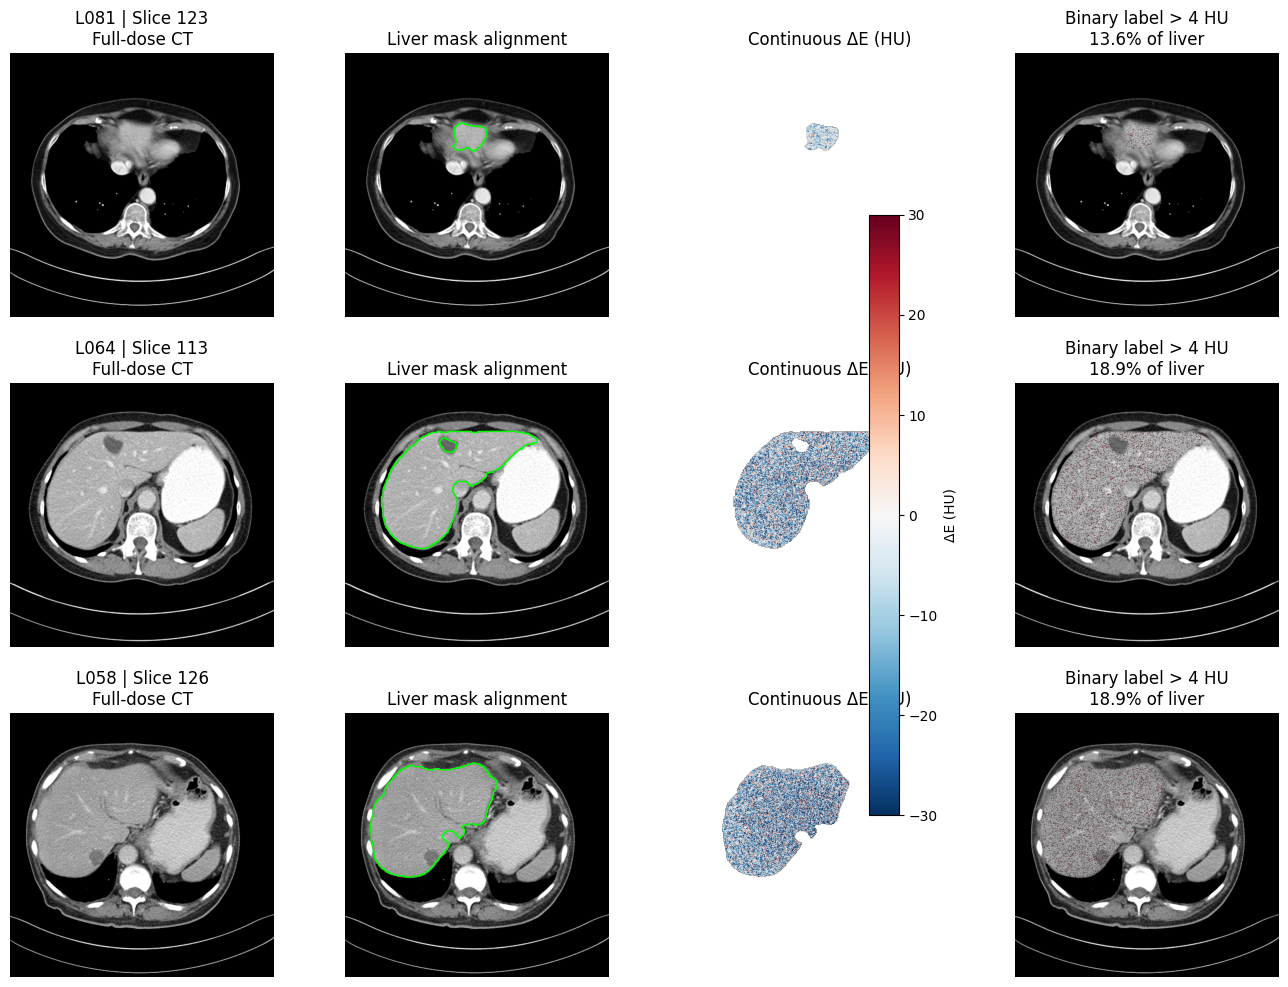

In [33]:
import matplotlib.pyplot as plt
from IPython.display import display

examples = qc.sample(3, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row_idx, (_, row) in enumerate(examples.iterrows()):
    case, z = row.case_id, int(row.slice)

    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        low = f["low_hu"][z].astype(np.float32)
        full = f["full_hu"][z].astype(np.float32)

    with np.load(root / "external_redcnn_final" / f"{case}.npz") as f:
        i = np.where(f["slices"] == z)[0][0]
        den = f["denoised_hu"][i]

    with np.load(root / "totalseg_final" / f"{case}.npz") as f:
        mask = f["mask"][i].astype(bool)

    with np.load(root / "alteration_labels_final" / f"{case}.npz") as f:
        labels = f["labels"][i].astype(bool)

    delta = np.abs(den - full) - np.abs(low - full)
    masked_delta = np.ma.masked_where(~mask, delta)

    ax = axes[row_idx]

    ax[0].imshow(full, cmap="gray", vmin=-150, vmax=250)
    ax[0].set_title(f"{case} | Slice {z}\nFull-dose CT")

    ax[1].imshow(full, cmap="gray", vmin=-150, vmax=250)
    ax[1].contour(mask, levels=[0.5], colors="lime", linewidths=1)
    ax[1].set_title("Liver mask alignment")

    im = ax[2].imshow(
        masked_delta, cmap="RdBu_r",
        vmin=-30, vmax=30
    )
    ax[2].set_title("Continuous ΔE (HU)")

    ax[3].imshow(full, cmap="gray", vmin=-150, vmax=250)
    ax[3].imshow(
        np.ma.masked_where(~labels, labels),
        cmap="Reds", vmin=0, vmax=1, alpha=0.65
    )
    percent = 100 * labels.sum() / mask.sum()

    ax[3].set_title(
    f"Binary label > 4 HU\n{percent:.1f}% of liver"
    )
    for a in ax:
        a.axis("off")

fig.colorbar(im, ax=axes[:, 2].tolist(),
             shrink=0.65, label="ΔE (HU)")
plt.subplots_adjust(wspace=0.12, hspace=0.25, right=0.94)
display(fig)
plt.close(fig)

> we splitted the dataset on patient level not ct slices to prevent leakage

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

root = Path("/kaggle/working/CAI421_processed")
folder = root / "alteration_labels_final"
output = folder / "five_fold_split.csv"

df = pd.read_csv(folder / "label_summary.csv")

assert len(df) == 41
assert df.case_id.nunique() == 16
assert not df.duplicated(["case_id", "slice"]).any()

# Freeze existing folds: never overwrite them
if output.exists():
    folds = pd.read_csv(output)
    print("Loaded existing frozen folds.")
else:
    df = df.sort_values(["case_id", "slice"]).reset_index(drop=True)

    cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)
    df["fold"] = -1

    for fold, (_, test_idx) in enumerate(
        cv.split(df, groups=df["case_id"]), start=1
    ):
        df.loc[test_idx, "fold"] = fold

    df.to_csv(output, index=False)
    folds = df
    print("Created and saved frozen folds.")

# Verify patient-level separation
assert len(folds) == 41
assert folds.case_id.nunique() == 16
assert folds.groupby("case_id")["fold"].nunique().eq(1).all()
assert set(folds.fold) == {1, 2, 3, 4, 5}

print("\nFold summary:")
print(folds.groupby("fold").agg(
    patients=("case_id", "nunique"),
    slices=("slice", "count"),
    mean_positive_percent=("altered_percent", "mean")
).round(2))

print("\nSaved:", output)

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/CAI421_processed/alteration_labels_final/label_summary.csv'

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import GroupShuffleSplit

root = Path("/kaggle/working/final files")

folds = pd.read_csv(
    root / "alteration_labels_final/five_fold_split.csv"
)

print("Patients:", folds["case_id"].nunique())
print("Slices:", len(folds))
print("GPU:", torch.cuda.is_available())

Patients: 16
Slices: 43
GPU: True


In [15]:
def load_cases(case_ids):
    volumes = []

    for case in case_ids:
        with (
            np.load(root / "pairs_raw_hu" / f"{case}.npz") as a,
            np.load(root / "external_redcnn_final" / f"{case}.npz") as d,
            np.load(root / "totalseg_final" / f"{case}.npz") as m,
            np.load(root / "alteration_labels_final" / f"{case}.npz") as y
        ):
            files = [a, d, m, y]
            keys = ["low_hu", "denoised_hu", "mask", "labels"]
            selected = folds.loc[folds.case_id == case, "slice"].to_numpy()

            arrays = []
            for data, key in zip(files, keys):
                arr = data[key]

                if "slices" in data.files:
                    indices = data["slices"]
                elif "slice_indices" in data.files:
                    indices = data["slice_indices"]
                else:
                    indices = np.arange(len(arr))

                positions = {int(s): i for i, s in enumerate(indices)}
                missing = set(selected) - set(positions)

                if missing:
                    raise ValueError(
                        f"{case}/{key}: missing slices {sorted(missing)}"
                    )

                arrays.append(
                    arr[[positions[int(s)] for s in selected]].astype(np.float32)
                )

            low, den, liver, label = arrays

            assert low.shape == den.shape == liver.shape == label.shape
            assert np.all(label <= liver)

            volumes.append({
                "low": (low + 1024) / 4096,
                "den": (den + 1024) / 4096,
                "mask": label,
                "lesion_mask": label,
                "valid_mask": liver
            })

    return volumes


In [16]:
from sklearn.model_selection import GroupShuffleSplit

def get_fold(fold):
    test = folds[folds.fold == fold]
    remaining = folds[folds.fold != fold]

    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    tr, va = next(splitter.split(remaining, groups=remaining.case_id))

    train_ids = remaining.iloc[tr].case_id.unique()
    val_ids = remaining.iloc[va].case_id.unique()
    test_ids = test.case_id.unique()

    assert set(train_ids).isdisjoint(val_ids)
    assert set(train_ids).isdisjoint(test_ids)
    assert set(val_ids).isdisjoint(test_ids)

    return load_cases(train_ids), load_cases(val_ids), load_cases(test_ids)


train_vols, val_vols, test_vols = get_fold(1)
print(f"Train: {len(train_vols)} | Val: {len(val_vols)} | Test: {len(test_vols)}")

Train: 9 | Val: 3 | Test: 4


## RiskMapUNet v2 architecture and training
The following model definition, loss, and crop sampler are retained from your uploaded notebook. The model receives **low-dose, external RED-CNN output, and their scaled difference**. The external RED-CNN remains frozen.

In [17]:
# 8 — Original RiskMapUNet v2, loss and patch sampler (from your Colab notebook).

import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

# ── Model ────────────────────────────────────────────────
class DoubleConv(nn.Module):
    def __init__(self, ci, co, drop=0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ci, co, 3, padding=1, bias=False),
            nn.GroupNorm(8, co), nn.ReLU(inplace=True),
            nn.Dropout2d(drop) if drop else nn.Identity(),
            nn.Conv2d(co, co, 3, padding=1, bias=False),
            nn.GroupNorm(8, co), nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class RiskMapUNet(nn.Module):
    def __init__(self, base=16, prior=1e-3, drop=0.1):
        super().__init__()
        c = base
        self.enc = nn.ModuleList([
            DoubleConv(3, c), DoubleConv(c, 2*c),
            DoubleConv(2*c, 4*c), DoubleConv(4*c, 8*c, drop)
        ])
        self.bott = DoubleConv(8*c, 16*c, drop)
        self.up = nn.ModuleList([
            nn.ConvTranspose2d(16*c, 8*c, 2, 2),
            nn.ConvTranspose2d(8*c, 4*c, 2, 2),
            nn.ConvTranspose2d(4*c, 2*c, 2, 2),
            nn.ConvTranspose2d(2*c, c, 2, 2)
        ])
        self.dec = nn.ModuleList([
            DoubleConv(16*c, 8*c), DoubleConv(8*c, 4*c),
            DoubleConv(4*c, 2*c), DoubleConv(2*c, c)
        ])
        self.head = nn.Conv2d(c, 1, 1)
        self.set_prior(prior)

    def set_prior(self, p):
        p = float(np.clip(p, 1e-6, 1-1e-6))
        nn.init.zeros_(self.head.weight)
        nn.init.constant_(self.head.bias, math.log(p/(1-p)))

    def forward(self, x):
        h, w = x.shape[-2:]
        ph, pw = (-h) % 16, (-w) % 16
        if ph or pw:
            mode = "reflect" if h > ph and w > pw else "replicate"
            x = F.pad(x, (0, pw, 0, ph), mode=mode)
        skips = []
        for enc in self.enc:
            x = enc(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.bott(x)
        for up, dec, skip in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), skip], 1))
        return self.head(x)[..., :h, :w]

    @torch.no_grad()
    def predict(self, x):
        was_training = self.training
        self.eval()
        p = torch.sigmoid(self(x))
        self.train(was_training)
        return p


def make_input(low, den, scale=10.0):
    return torch.stack([low, den, (den-low)*scale], dim=1)


# ── Loss ─────────────────────────────────────────────────
class AlterationLoss(nn.Module):
    def __init__(self, pos_weight=20, alpha=.3, beta=.7,
                 gamma=.75, tv_weight=.5):
        super().__init__()
        self.pw, self.a, self.b = pos_weight, alpha, beta
        self.g, self.tw = gamma, tv_weight

    def forward(self, logits, target, valid=None):
        target = target.float()
        valid = torch.ones_like(target) if valid is None else valid.float()
        if valid.sum() == 0:
            return logits.sum() * 0

        pw = torch.as_tensor(self.pw, device=logits.device, dtype=logits.dtype)
        bce = F.binary_cross_entropy_with_logits(
            logits, target, pos_weight=pw, reduction="none"
        )
        bce = (bce * valid).sum() / valid.sum()

        p, y = torch.sigmoid(logits)*valid, target*valid
        if y.sum() == 0:
            return bce

        tp = (p*y).sum()
        fp = (p*(1-y)).sum()
        fn = ((1-p)*y).sum()
        tv = 1 - (tp+1e-6)/(tp+self.a*fp+self.b*fn+1e-6)
        return bce + self.tw*tv.pow(self.g)


# ── Crop sampler ─────────────────────────────────────────
class CropSampler:
    """Each volume: low, den, mask, lesion_mask, optional valid_mask."""
    def __init__(self, volumes, crop=128, seed=0, augment=True):
        self.vols, self.crop, self.augment = volumes, crop, augment
        self.rng = np.random.default_rng(seed)
        self.pos = [np.argwhere(v["mask"] > 0) for v in volumes]
        self.les = [np.argwhere(v["lesion_mask"] > 0) for v in volumes]
        self.pos_ids = [i for i, a in enumerate(self.pos) if len(a)]
        self.les_ids = [i for i, a in enumerate(self.les) if len(a)]
        for v in volumes:
            assert v["mask"].shape[1] >= crop and v["mask"].shape[2] >= crop

    def one(self):
        r, c = self.rng, self.crop
        mode = r.choice(3, p=[.4, .4, .2])
        ids = self.pos_ids if mode == 0 else self.les_ids if mode == 1 else []
        coords = self.pos if mode == 0 else self.les

        if ids:
            i = int(r.choice(ids))
            z, y, x = coords[i][r.integers(len(coords[i]))]
            y += r.integers(-c//3, c//3+1)
            x += r.integers(-c//3, c//3+1)
        else:
            i = int(r.integers(len(self.vols)))
            Z, H, W = self.vols[i]["mask"].shape
            z, y, x = r.integers(Z), r.integers(H), r.integers(W)

        v = self.vols[i]
        _, H, W = v["mask"].shape
        y0 = int(np.clip(y-c//2, 0, H-c))
        x0 = int(np.clip(x-c//2, 0, W-c))
        sl = (int(z), slice(y0, y0+c), slice(x0, x0+c))

        keys = ["low", "den", "mask"]
        a = [np.asarray(v[k][sl], dtype=np.float32) for k in keys]
        valid = v.get("valid_mask")
        a.append(np.asarray(valid[sl], dtype=np.float32)
                 if valid is not None else np.ones((c, c), np.float32))

        if self.augment:
            if r.random() < .5: a = [q[:, ::-1] for q in a]
            if r.random() < .5: a = [q[::-1] for q in a]
            k = int(r.integers(4))
            a = [np.rot90(q, k) for q in a]
        return [np.ascontiguousarray(q) for q in a]

    def batch(self, n=8, device="cpu"):
        L, D, Y, V = zip(*(self.one() for _ in range(n)))
        t = lambda a: torch.from_numpy(np.stack(a)).to(device)
        return make_input(t(L), t(D)), t(Y)[:, None], t(V)[:, None]

    def positive_rate(self, n=200):
        return float(np.mean([self.one()[2].mean() for _ in range(n)]))


# ── Metrics ──────────────────────────────────────────────
@torch.no_grad()
def metrics(logits, target, threshold=.5, valid=None):
    p = torch.sigmoid(logits) >= threshold
    y = target.bool()
    v = torch.ones_like(y) if valid is None else valid.bool()
    tp = (p & y & v).sum().item()
    fp = (p & ~y & v).sum().item()
    fn = (~p & y & v).sum().item()
    eps = 1e-8
    return {
        "dice": 2*tp/(2*tp+fp+fn+eps),
        "iou": tp/(tp+fp+fn+eps),
        "precision": tp/(tp+fp+eps),
        "recall": tp/(tp+fn+eps),
        "tp": tp, "fp": fp, "fn": fn
    }


# ── Quick sanity check (no training or saving) ───────────
device = "cuda" if torch.cuda.is_available() else "cpu"
net = RiskMapUNet().to(device)
x = torch.randn(1, 3, 128, 128, device=device)
y = torch.zeros(1, 1, 128, 128, device=device)
y[:, :, 60:68, 60:68] = 1

logits = net(x)
loss = AlterationLoss()(logits, y)
loss.backward()

print("Device:", device)
print("Parameters:", f"{sum(p.numel() for p in net.parameters()):,}")
print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 4))
print("Backward pass:", "OK")


Device: cuda
Parameters: 1,942,577
Output shape: (1, 1, 128, 128)
Loss: 1.0402
Backward pass: OK


TRAINING PART

In [19]:
@torch.no_grad()
def validate(model, volumes, criterion):
    model.eval()
    total, count = 0., 0

    for v in volumes:
        for i in range(len(v["low"])):
            low = torch.from_numpy(v["low"][i:i+1]).to(device)
            den = torch.from_numpy(v["den"][i:i+1]).to(device)
            y = torch.from_numpy(v["mask"][i:i+1, None]).to(device)
            liver = torch.from_numpy(v["valid_mask"][i:i+1, None]).to(device)

            loss = criterion(model(make_input(low, den)), y, liver)
            total += loss.item()
            count += 1

    return total / count

the result we got after training and validating 

*Fold 1 complete | Best validation loss: 2.3603*

*Fold 2 complete | Best validation loss: 2.4154*

*Fold 3 complete | Best validation loss: 2.4539*

*Fold 4 complete | Best validation loss: 2.4501*

*Fold 5 complete | Best validation loss: 2.4235*


In [27]:
save_dir = Path("/kaggle/working/RiskMapUNet_v2_final")
save_dir.mkdir(exist_ok=True)

for fold in range(1, 6):
    train_vols, val_vols, _ = get_fold(fold)

    torch.manual_seed(42 + fold)
    model = RiskMapUNet().to(device)
    loss_fn = AlterationLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
    sampler = CropSampler(train_vols, crop=128, seed=42 + fold)

    best, patience = float("inf"), 0

    for epoch in range(1, 101):
        model.train()
        losses = []

        for _ in range(50):
            x, y, liver = sampler.batch(4, device)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(x), y, liver)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        val = validate(model, val_vols, loss_fn)

        if val < best - 1e-4:
            best, patience = val, 0
            torch.save(model.state_dict(), save_dir / f"fold_{fold}.pt")
        else:
            patience += 1

        if epoch == 1 or epoch % 5 == 0:
            print(f"Fold {fold} | Epoch {epoch} | "
                  f"Train {np.mean(losses):.4f} | Val {val:.4f}")

        if patience >= 12:
            break

    print(f"Fold {fold} complete | Best validation loss: {best:.4f}")

Fold 1 | Epoch 1 | Train 25.6295 | Val 24.6480
Fold 1 | Epoch 5 | Train 24.3199 | Val 22.0369
Fold 1 | Epoch 10 | Train 22.6102 | Val 18.1840
Fold 1 | Epoch 15 | Train 20.3627 | Val 13.7825
Fold 1 | Epoch 20 | Train 17.9706 | Val 9.7506
Fold 1 | Epoch 25 | Train 15.4798 | Val 6.6436
Fold 1 | Epoch 30 | Train 12.6093 | Val 3.7770
Fold 1 | Epoch 35 | Train 11.0879 | Val 2.8765
Fold 1 | Epoch 40 | Train 8.9623 | Val 2.5807
Fold 1 | Epoch 45 | Train 7.3449 | Val 2.5306
Fold 1 | Epoch 50 | Train 6.1223 | Val 2.5761
Fold 1 | Epoch 55 | Train 4.7923 | Val 2.4693
Fold 1 | Epoch 60 | Train 4.4537 | Val 2.5991
Fold 1 | Epoch 65 | Train 3.6744 | Val 2.3996
Fold 1 | Epoch 70 | Train 3.5027 | Val 2.4490
Fold 1 | Epoch 75 | Train 3.1452 | Val 2.4288
Fold 1 | Epoch 80 | Train 2.9350 | Val 2.4041
Fold 1 | Epoch 85 | Train 2.7366 | Val 2.3815
Fold 1 | Epoch 90 | Train 2.6086 | Val 2.3694
Fold 1 | Epoch 95 | Train 2.5536 | Val 2.3634
Fold 1 | Epoch 100 | Train 2.5278 | Val 2.3625
Fold 1 complete | Best 

TEST PART

Testing evaluates how well RiskMapUNet detects liver alterations in unseen patients 
as a result very high recall (99.49%) but low precision (18.43%) creating more false positive


In [28]:
from sklearn.metrics import average_precision_score

results = []

for fold in range(1, 6):
    _, _, test_vols = get_fold(fold)

    model = RiskMapUNet().to(device)
    model.load_state_dict(torch.load(
        save_dir / f"fold_{fold}.pt",
        map_location=device,
        weights_only=True
    ))
    model.eval()

    tp = fp = fn = 0
    targets, probabilities = [], []

    with torch.no_grad():
        for v in test_vols:
            for i in range(len(v["low"])):
                low = torch.from_numpy(v["low"][i:i+1]).to(device)
                den = torch.from_numpy(v["den"][i:i+1]).to(device)

                prob = model.predict(make_input(low, den))[0, 0].cpu().numpy()
                liver = v["valid_mask"][i].astype(bool)
                y = v["mask"][i][liver].astype(bool)
                p = prob[liver]
                pred = p >= 0.5

                tp += np.sum(pred & y)
                fp += np.sum(pred & ~y)
                fn += np.sum(~pred & y)
                targets.append(y)
                probabilities.append(p)

    y = np.concatenate(targets)
    p = np.concatenate(probabilities)

    results.append({
        "fold": fold,
        "dice": 2*tp / (2*tp + fp + fn + 1e-8),
        "iou": tp / (tp + fp + fn + 1e-8),
        "precision": tp / (tp + fp + 1e-8),
        "recall": tp / (tp + fn + 1e-8),
        "auprc": average_precision_score(y, p)
    })

results = pd.DataFrame(results)
print(results.round(4))
print("\nMean ± SD")
print(results.drop(columns="fold").agg(["mean", "std"]).round(4))

results.to_csv(save_dir / "five_fold_results.csv", index=False)

   fold    dice     iou  precision  recall   auprc
0     1  0.3058  0.1805     0.1805  0.9981  0.2329
1     2  0.3261  0.1948     0.1952  0.9882  0.2191
2     3  0.2953  0.1732     0.1732  0.9997  0.1924
3     4  0.3320  0.1990     0.1992  0.9968  0.2577
4     5  0.2954  0.1733     0.1735  0.9918  0.1853

Mean ± SD
        dice     iou  precision  recall   auprc
mean  0.3109  0.1842     0.1843  0.9949  0.2175
std   0.0172  0.0121     0.0122  0.0048  0.0297


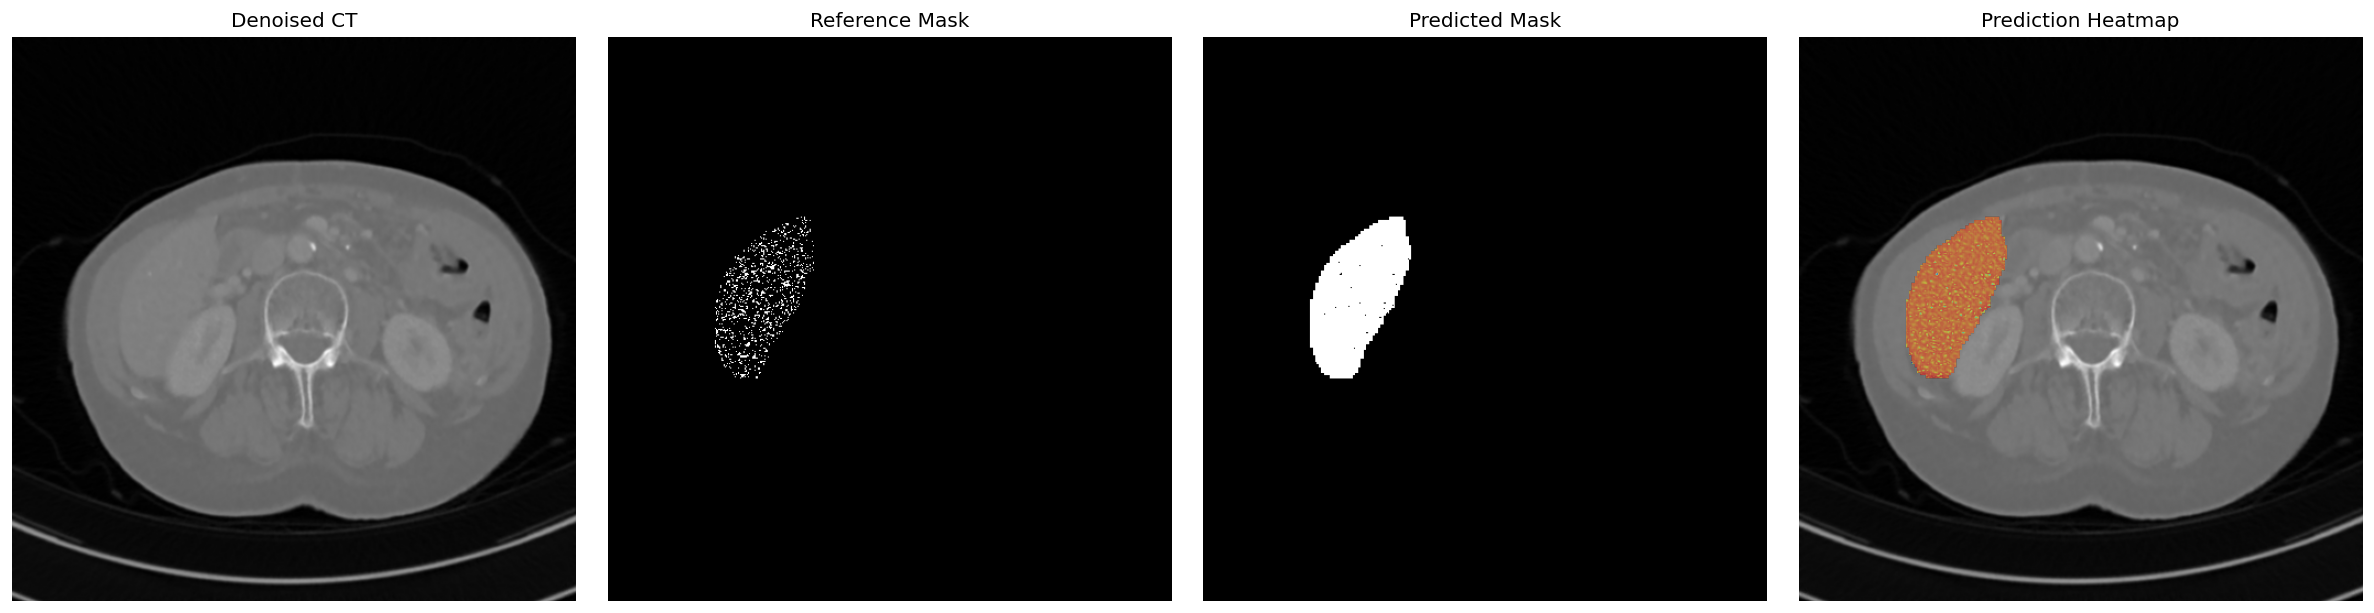

In [35]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

item = val_vols[0]
s = 0  # Slice index: 0–3

def to_np(x):
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)

low = torch.as_tensor(item["low"][s:s+1], dtype=torch.float32, device=device)
den = torch.as_tensor(item["den"][s:s+1], dtype=torch.float32, device=device)

model.eval()
with torch.no_grad():
    logits = model(make_input(low, den))
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

den = to_np(item["den"][s])
truth = to_np(item["lesion_mask"][s])
liver = to_np(item["valid_mask"][s])
prediction = (probability >= 0.5) & (liver > 0)

fig, axes = plt.subplots(1, 4, figsize=(20, 5), dpi=120)

for ax, img, title in zip(
    axes[:3],
    [den, truth, prediction],
    ["Denoised CT", "Reference Mask", "Predicted Mask"]
):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

axes[3].imshow(den, cmap="gray")
axes[3].imshow(
    np.ma.masked_where(liver == 0, probability),
    cmap="jet", alpha=0.5, vmin=0, vmax=1
)
axes[3].set_title("Prediction Heatmap")
axes[3].axis("off")

fig.tight_layout()
display(fig)
plt.close(fig)

In [37]:
from pathlib import Path
import numpy as np
import torch

def to_np(x):
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)

out.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    out / "fold1_test_example.npz",
    low=to_np(low),
    den=to_np(den),
    truth=to_np(truth),
    prediction=to_np(prediction),
    liver=to_np(liver),
    probability=to_np(probability)
)

print("Saved:", out / "fold1_test_example.npz")

Saved: /kaggle/working/Model_Comparison/RiskMapUNet/predictions/fold1_test_example.npz


# Baseline 1- AttentionUnet

In [39]:
from pathlib import Path
import random, gc, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
#Reuse existing imports, root, and fold definitions
BASE_OUT = Path("/kaggle/working/CAI421_results/baseline_attention_unet")
BASE_OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
CROP_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 20
SAMPLES_PER_EPOCH = 64
LEARNING_RATE = 1e-4
BASE_CHANNELS = 16
PATIENCE = 6
THRESHOLD = 0.50

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reuse the existing processed dataset
BASE_RAW = root / "pairs_raw_hu"
BASE_RED = root / "external_redcnn_final"
BASE_LIVER = root / "totalseg_final"
BASE_LABELS = root / "alteration_labels_final"

In [40]:

# Use the same frozen five-fold split
fold_df = folds.copy()

assert len(fold_df) == 43, "Expected 43 finalized approved slices"
assert fold_df.case_id.nunique() == 16
assert fold_df.groupby("case_id").fold.nunique().eq(1).all()
assert set(fold_df.fold.unique()) == {1, 2, 3, 4, 5}
assert not fold_df.duplicated(["case_id", "slice"]).any()

print("Device:", DEVICE)
print("Patients:", fold_df.case_id.nunique())
print("Slices:", len(fold_df))

display(fold_df.groupby("fold").agg(
    patients=("case_id", "nunique"),
    slices=("slice", "count")
))


Device: cuda
Patients: 16
Slices: 43


,patients,slices
fold,,
1,4,14
2,3,10
3,3,7
4,3,4
5,3,8


In [41]:
# ----------------------------------------------------
# 3. Aligned slice loading and input preparation
# ----------------------------------------------------

records = []

for row in fold_df.sort_values(["case_id", "slice"]).itertuples(index=False):
    case_id = str(row.case_id)
    slice_id = int(row.slice)
    fold = int(row.fold)

    # Low-dose CT
    with np.load(BASE_RAW / f"{case_id}.npz", allow_pickle=False) as data:
        low_hu = data["low_hu"][slice_id].astype(np.float32)

    # Match each processed output to its original slice index
    def load_aligned_slice(folder, key):
        with np.load(folder / f"{case_id}.npz", allow_pickle=False) as data:
            positions = np.where(data["slices"].astype(int) == slice_id)[0]

            if len(positions) != 1:
                raise ValueError(
                    f"{case_id}, slice {slice_id}: {key} alignment failed"
                )

            return data[key][int(positions[0])].copy()

    den_hu = load_aligned_slice(BASE_RED, "denoised_hu").astype(np.float32)
    liver = load_aligned_slice(BASE_LIVER, "mask").astype(np.uint8)
    target = load_aligned_slice(BASE_LABELS, "labels").astype(np.uint8)

    # Verify image dimensions and liver-label consistency
    if not (low_hu.shape == den_hu.shape == liver.shape == target.shape):
        raise ValueError(f"Shape mismatch: {case_id}, slice {slice_id}")

    if low_hu.shape != (512, 512):
        raise ValueError(f"Unexpected image size: {case_id}, slice {slice_id}")

    if liver.sum() == 0:
        raise ValueError(f"Empty liver mask: {case_id}, slice {slice_id}")

    if np.any((target > 0) & (liver == 0)):
        raise ValueError(
            f"Alteration labels outside liver: {case_id}, slice {slice_id}"
        )

    # Original baseline HU window
    low = np.clip((low_hu + 160.0) / 400.0, 0, 1)
    den = np.clip((den_hu + 160.0) / 400.0, 0, 1)

    # Three-channel Attention U-Net input
    x = np.stack(
        [low, den, (den - low) * 10.0],
        axis=0
    ).astype(np.float32)

    records.append({
        "case_id": case_id,
        "slice": slice_id,
        "fold": fold,
        "x": x,
        "y": target.astype(np.float32),
        "valid": liver.astype(np.float32)
    })

print(
    f"Loaded {len(records)} aligned slices from "
    f"{len(set(r['case_id'] for r in records))} patients."
)

positive_fraction = (
    sum(r["y"].sum() for r in records) /
    max(1, sum(r["valid"].sum() for r in records))
)

print("Mean positive-pixel fraction inside liver:", round(positive_fraction, 4))

Loaded 43 aligned slices from 16 patients.
Mean positive-pixel fraction inside liver: 0.1788


In [42]:
# ---------------------------------------
# 4. Liver-centered patch sampling and augmentation
# ---------------------------------------

class LiverPatchDataset(Dataset):
    def __init__(self, items, samples, crop=256, augment=True, seed=42):
        self.items = items
        self.samples = samples
        self.crop = crop
        self.augment = augment
        self.rng = np.random.default_rng(seed)

        # Identify eligible sampling locations within the liver
        self.coords = [
            np.argwhere(item["valid"] > 0)
            for item in items
        ]

        if any(len(coords) == 0 for coords in self.coords):
            raise ValueError("A training slice contains an empty liver mask.")

    def __len__(self):
        return self.samples

    def __getitem__(self, index):

        # Randomly select a training slice and liver-centered location
        item_id = int(self.rng.integers(len(self.items)))
        item = self.items[item_id]

        center = self.coords[item_id][
            self.rng.integers(len(self.coords[item_id]))
        ]
        cy, cx = map(int, center)

        # Extract a fixed-size patch within image boundaries
        half = self.crop // 2

        y0 = int(np.clip(cy - half, 0, 512 - self.crop))
        x0 = int(np.clip(cx - half, 0, 512 - self.crop))

        region = (
            slice(y0, y0 + self.crop),
            slice(x0, x0 + self.crop)
        )

        x = item["x"][:, region[0], region[1]].copy()
        y = item["y"][region].copy()
        valid = item["valid"][region].copy()

        # Apply identical spatial transformations to all three arrays
        if self.augment:

            if self.rng.random() < 0.5:
                x = x[:, :, ::-1]
                y = y[:, ::-1]
                valid = valid[:, ::-1]

            if self.rng.random() < 0.5:
                x = x[:, ::-1, :]
                y = y[::-1, :]
                valid = valid[::-1, :]

            k = int(self.rng.integers(4))

            x = np.rot90(x, k, axes=(1, 2))
            y = np.rot90(y, k)
            valid = np.rot90(valid, k)

        # Return contiguous tensors for model training
        return (
            torch.from_numpy(np.ascontiguousarray(x)).float(),
            torch.from_numpy(np.ascontiguousarray(y[None])).float(),
            torch.from_numpy(np.ascontiguousarray(valid[None])).float()
        )

In [43]:
# ---------------------------------------
# 5. Attention U-Net model architecture
# ---------------------------------------

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        groups = 8 if out_ch % 8 == 0 else 1

        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class AttentionGate(nn.Module):
    def __init__(self, gate_ch, skip_ch, inter_ch):
        super().__init__()

        self.gate_proj = nn.Sequential(
            nn.Conv2d(gate_ch, inter_ch, kernel_size=1, bias=True),
            nn.GroupNorm(1, inter_ch)
        )

        self.skip_proj = nn.Sequential(
            nn.Conv2d(skip_ch, inter_ch, kernel_size=1, bias=True),
            nn.GroupNorm(1, inter_ch)
        )

        self.score = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(inter_ch, 1, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, gate, skip):

        # Align spatial dimensions before attention weighting
        if gate.shape[-2:] != skip.shape[-2:]:
            gate = F.interpolate(
                gate,
                size=skip.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        attention = self.score(
            self.gate_proj(gate) + self.skip_proj(skip)
        )

        return skip * attention


class AttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base=16):
        super().__init__()

        b = base
        self.pool = nn.MaxPool2d(kernel_size=2)

        # Encoder
        self.enc1 = ConvBlock(in_channels, b)
        self.enc2 = ConvBlock(b, 2 * b)
        self.enc3 = ConvBlock(2 * b, 4 * b)
        self.enc4 = ConvBlock(4 * b, 8 * b)

        # Bottleneck
        self.bottleneck = ConvBlock(8 * b, 16 * b)

        # Decoder with attention-gated skip connections
        self.up4 = nn.ConvTranspose2d(16 * b, 8 * b, 2, stride=2)
        self.att4 = AttentionGate(8 * b, 8 * b, 4 * b)
        self.dec4 = ConvBlock(16 * b, 8 * b)

        self.up3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, stride=2)
        self.att3 = AttentionGate(4 * b, 4 * b, 2 * b)
        self.dec3 = ConvBlock(8 * b, 4 * b)

        self.up2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, stride=2)
        self.att2 = AttentionGate(2 * b, 2 * b, b)
        self.dec2 = ConvBlock(4 * b, 2 * b)

        self.up1 = nn.ConvTranspose2d(2 * b, b, 2, stride=2)
        self.att1 = AttentionGate(b, b, max(1, b // 2))
        self.dec1 = ConvBlock(2 * b, b)

        # Single-channel segmentation output
        self.head = nn.Conv2d(b, out_channels, kernel_size=1)

    def forward(self, x):

        height, width = x.shape[-2:]

        # Pad dimensions to support four downsampling stages
        pad_h = (-height) % 16
        pad_w = (-width) % 16

        if pad_h or pad_w:
            x = F.pad(
                x,
                (0, pad_w, 0, pad_h),
                mode="replicate"
            )

        # Encoding
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        bottleneck = self.bottleneck(self.pool(e4))

        # Attention-guided decoding
        d4 = self.up4(bottleneck)
        d4 = self.dec4(torch.cat(
            [d4, self.att4(d4, e4)], dim=1
        ))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat(
            [d3, self.att3(d3, e3)], dim=1
        ))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat(
            [d2, self.att2(d2, e2)], dim=1
        ))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat(
            [d1, self.att1(d1, e1)], dim=1
        ))

        # Restore original spatial dimensions
        return self.head(d1)[..., :height, :width]

In [44]:
# ---------------------------------------
# 6. Liver-masked loss and evaluation metrics
# ---------------------------------------

class MaskedBCEDiceLoss(nn.Module):
    def __init__(self, pos_weight=3.0, dice_weight=1.0):
        super().__init__()

        self.register_buffer(
            "pos_weight",
            torch.tensor(float(pos_weight))
        )
        self.dice_weight = dice_weight

    def forward(self, logits, target, valid):

        # Weighted binary cross-entropy within the liver
        bce_map = F.binary_cross_entropy_with_logits(
            logits,
            target,
            reduction="none",
            pos_weight=self.pos_weight
        )

        bce = (
            (bce_map * valid).sum() /
            valid.sum().clamp_min(1.0)
        )

        # Soft Dice loss within the same region
        probabilities = torch.sigmoid(logits) * valid
        target = target * valid

        dims = (1, 2, 3)

        intersection = (probabilities * target).sum(dims)
        denominator = probabilities.sum(dims) + target.sum(dims)

        dice = (
            (2 * intersection + 1e-6) /
            (denominator + 1e-6)
        )

        dice_loss = 1 - dice.mean()

        return bce + self.dice_weight * dice_loss


@torch.no_grad()
def evaluate_attention_model(model, items):

    model.eval()

    tp = fp = fn = 0
    losses = []

    criterion = MaskedBCEDiceLoss().to(DEVICE)

    for item in items:

        # Prepare full-resolution inputs and masks
        x = torch.from_numpy(
            item["x"][None]
        ).float().to(DEVICE)

        y = torch.from_numpy(
            item["y"][None, None]
        ).float().to(DEVICE)

        valid = torch.from_numpy(
            item["valid"][None, None]
        ).float().to(DEVICE)

        # Generate predictions and calculate masked loss
        logits = model(x)

        losses.append(
            float(criterion(logits, y, valid).item())
        )

        # Apply the fixed threshold within the liver
        prediction = (
            (torch.sigmoid(logits) >= THRESHOLD) &
            (valid > 0)
        )

        reference = (y > 0.5) & (valid > 0)

        # Accumulate pixel-level confusion counts
        tp += int((prediction & reference).sum().item())

        fp += int(
            (prediction & ~reference & (valid > 0))
            .sum().item()
        )

        fn += int(
            (~prediction & reference).sum().item()
        )

        del x, y, valid, logits

    # Compute aggregate segmentation metrics
    eps = 1e-8

    return {
        "loss": float(np.mean(losses)),
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "iou": tp / (tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps),
        "tp": tp,
        "fp": fp,
        "fn": fn
    }

In [45]:
# Set reproducible random seeds for each fold
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
# ------------------------------------------
# 7. Five-fold patient-level cross-validation
# ------------------------------------------
# Each fold is held out once for validation. No patient appears in both sets.
fold_results = []
for held_out_fold in range(1, 6):
    print(f"\n{'='*18} FOLD {held_out_fold}/5 {'='*18}")
    train_items = [r for r in records if r["fold"] != held_out_fold]
    val_items = [r for r in records if r["fold"] == held_out_fold]

    train_patients = {r["case_id"] for r in train_items}
    val_patients = {r["case_id"] for r in val_items}
    assert train_patients.isdisjoint(val_patients)
    print("Train patients:", len(train_patients), "| validation patients:", len(val_patients))
    print("Train slices:", len(train_items), "| validation slices:", len(val_items))

    set_seed(SEED + held_out_fold)
    train_ds = LiverPatchDataset(
        train_items, samples=SAMPLES_PER_EPOCH, crop=CROP_SIZE,
        augment=True, seed=SEED + held_out_fold
    )
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=0, pin_memory=(DEVICE.type == "cuda")
    )

    model = AttentionUNet(base=BASE_CHANNELS).to(DEVICE)
    criterion = MaskedBCEDiceLoss(pos_weight=3.0, dice_weight=1.0).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    best_dice = -1.0
    best_epoch = 0
    bad_epochs = 0
    best_path = BASE_OUT / f"attention_unet_fold_{held_out_fold}_best.pt"

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_losses = []
        for x, y, valid in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            valid = valid.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y, valid)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_losses.append(float(loss.item()))

        val_metrics = evaluate_attention_model(model, val_items)
        scheduler.step(val_metrics["dice"])
        print(
            f"Fold {held_out_fold} | Epoch {epoch:02d}/{EPOCHS} "
            f"| train_loss={np.mean(train_losses):.4f} "
            f"| val_dice={val_metrics['dice']:.4f} "
            f"| val_iou={val_metrics['iou']:.4f}"
        )

        if val_metrics["dice"] > best_dice:
            best_dice = val_metrics["dice"]
            best_epoch = epoch
            bad_epochs = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "fold": held_out_fold,
                "epoch": epoch,
                "validation_metrics": val_metrics,
                "threshold": THRESHOLD,
                "input_channels": ["low_dose", "external_redcnn", "difference_x10"]
            }, best_path)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print("Early stopping.")
                break

    # Reload the best checkpoint and record held-out fold metrics.
    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    final_metrics = evaluate_attention_model(model, val_items)
    final_metrics.update({
        "fold": held_out_fold,
        "best_epoch": best_epoch,
        "train_patients": len(train_patients),
        "validation_patients": len(val_patients),
        "train_slices": len(train_items),
        "validation_slices": len(val_items),
        "checkpoint": str(best_path)
    })
    fold_results.append(final_metrics)
    print("Best fold result:", final_metrics)

    del model, optimizer, criterion, train_loader, train_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()



================== FOLD 1/5 ==================
Train patients: 12 | validation patients: 4
Train slices: 29 | validation slices: 14
Fold 1 | Epoch 01/20 | train_loss=1.6888 | val_dice=0.0587 | val_iou=0.0302
Fold 1 | Epoch 02/20 | train_loss=1.6631 | val_dice=0.0444 | val_iou=0.0227
Fold 1 | Epoch 03/20 | train_loss=1.6574 | val_dice=0.0192 | val_iou=0.0097
Fold 1 | Epoch 04/20 | train_loss=1.6493 | val_dice=0.0174 | val_iou=0.0088
Fold 1 | Epoch 05/20 | train_loss=1.6487 | val_dice=0.0277 | val_iou=0.0140
Fold 1 | Epoch 06/20 | train_loss=1.6500 | val_dice=0.0358 | val_iou=0.0182
Fold 1 | Epoch 07/20 | train_loss=1.6382 | val_dice=0.0451 | val_iou=0.0231
Early stopping.
Best fold result: {'loss': 1.6674654654094152, 'dice': 0.05866180173697792, 'iou': 0.030217198522887217, 'precision': 0.1900757638829489, 'recall': 0.03468287124951999, 'tp': 2283, 'fp': 9728, 'fn': 63542, 'fold': 1, 'best_epoch': 1, 'train_patients': 12, 'validation_patients': 4, 'train_slices': 29, 'validation_slice

In [51]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score
from IPython.display import display

metric_cols = ["dice", "iou", "precision", "recall", "auprc"]

for result in fold_results:
    fold = result["fold"]
    items = [r for r in records if r["fold"] == fold]

    checkpoint = torch.load(result["checkpoint"], map_location=DEVICE, weights_only=False)
    model = AttentionUNet().to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    probs, labels = [], []

    with torch.no_grad():
        for item in items:
            x = torch.as_tensor(item["x"][None], dtype=torch.float32, device=DEVICE)
            y = np.asarray(item["y"])
            valid = np.asarray(item["valid"]) > 0

            p = torch.sigmoid(model(x))[0, 0].cpu().numpy()
            probs.append(p[valid].ravel())
            labels.append(y[valid].ravel())

    probs, labels = np.concatenate(probs), np.concatenate(labels)
    result["auprc"] = (
        float(average_precision_score(labels, probs))
        if np.any(labels) else np.nan
    )

    print(f"Fold {fold}: AUPRC = {result['auprc']:.4f}")
    del model

results_df = pd.DataFrame(fold_results)
summary = results_df[metric_cols].agg(["mean", "std"]).round(4)

results_path = BASE_OUT / "attention_unet_5fold_metrics.csv"
summary_path = BASE_OUT / "attention_unet_5fold_summary.csv"

results_df.to_csv(results_path, index=False)
summary.to_csv(summary_path)

print("\nATTENTION U-NET — FIVE-FOLD RESULTS")
display(results_df[["fold", "best_epoch", *metric_cols]].round(4))
display(summary)
print("Saved:", results_path, summary_path)

Fold 1: AUPRC = 0.1848
Fold 2: AUPRC = 0.2270
Fold 3: AUPRC = 0.1997
Fold 4: AUPRC = 0.1998
Fold 5: AUPRC = 0.1955

ATTENTION U-NET — FIVE-FOLD RESULTS


,fold,best_epoch,dice,iou,precision,recall,auprc
0,1,1,0.0587,0.0302,0.1901,0.0347,0.1848
1,2,18,0.2758,0.1600,0.2325,0.3390,0.2270
2,3,19,0.2211,0.1243,0.2030,0.2427,0.1997
3,4,1,0.0796,0.0414,0.1972,0.0499,0.1998
4,5,18,0.2764,0.1603,0.1946,0.4769,0.1955


,dice,iou,precision,recall,auprc
mean,0.1823,0.1032,0.2035,0.2286,0.2014
std,0.1060,0.0634,0.0169,0.1895,0.0156


Saved: /kaggle/working/CAI421_results/baseline_attention_unet/attention_unet_5fold_metrics.csv /kaggle/working/CAI421_results/baseline_attention_unet/attention_unet_5fold_summary.csv


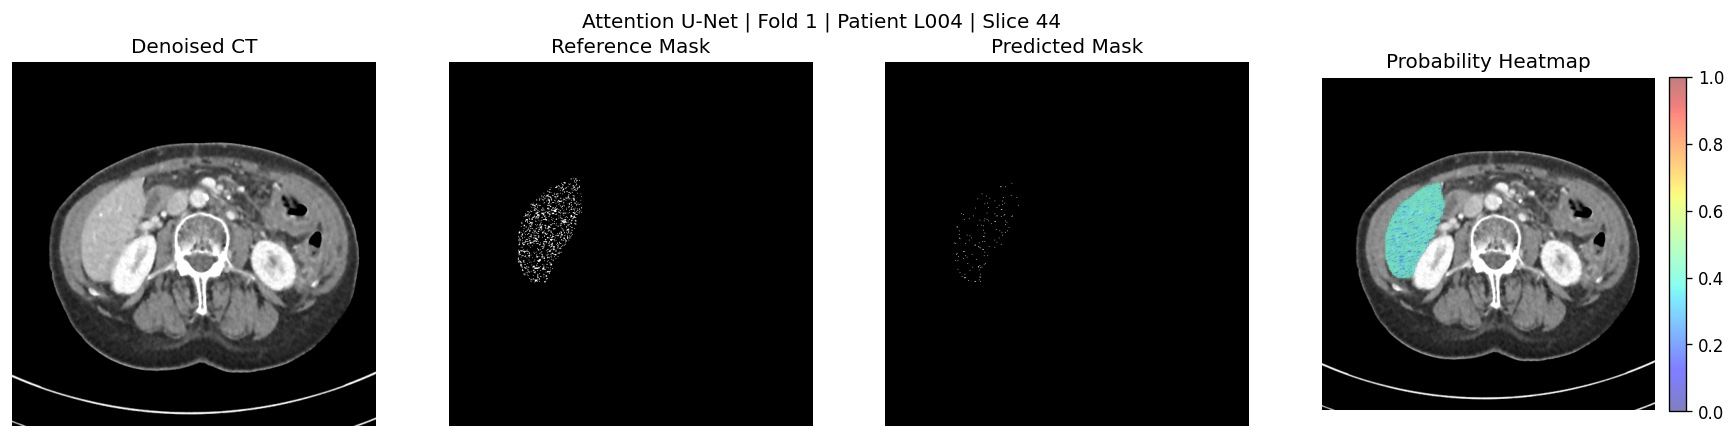

In [67]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

fold = 1
attention_dir = Path("/kaggle/working/CAI421_results/baseline_attention_unet")
path = attention_dir / f"attention_unet_fold_{fold}_best.pt"

item = next(r for r in records if r["fold"] == fold and np.any(r["y"]))

checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
model = AttentionUNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

x = torch.as_tensor(item["x"][None], dtype=torch.float32, device=DEVICE)

with torch.no_grad():
    prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()

den = item["x"][1]
truth = item["y"] > 0.5
liver = item["valid"] > 0
pred = (prob >= 0.5) & liver

fig, ax = plt.subplots(1, 4, figsize=(18, 4), dpi=120)

images = [den, truth, pred]
titles = ["Denoised CT", "Reference Mask", "Predicted Mask"]

for i in range(3):
    ax[i].imshow(images[i], cmap="gray")
    ax[i].set_title(titles[i])

ax[3].imshow(den, cmap="gray")
heat = ax[3].imshow(
    np.ma.masked_where(~liver, prob),
    cmap="jet", alpha=0.5, vmin=0, vmax=1
)
ax[3].set_title("Probability Heatmap")

for a in ax:
    a.axis("off")

fig.colorbar(heat, ax=ax[3], fraction=0.046, pad=0.04)
fig.suptitle(
    f"Attention U-Net | Fold {fold} | "
    f"Patient {item['case_id']} | Slice {item['slice']}"
)
plt.show()

# Baseline 2- ResDUnet

In [2]:
from pathlib import Path

for root in ["/kaggle/working", "/kaggle/input"]:
    files = list(Path(root).rglob("*.pt"))
    print(f"\n{root}: {len(files)} checkpoints")
    for p in files[:30]:
        print(p)


/kaggle/working: 0 checkpoints

/kaggle/input: 1 checkpoints
/kaggle/input/datasets/ramalg/cai421-liver-lesion-detection-part-3/CAI421_processed-20261112T185000Z-1-002/CAI421_processed/models/red_cnn/red_cnn_best.pt


In [3]:
from pathlib import Path
import random, gc, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [4]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

BASE_ROOT = Path("/kaggle/working/CAI421_processed")
BASE_RAW = BASE_ROOT / "pairs_raw_hu"
BASE_RED = BASE_ROOT / "external_redcnn_final"
BASE_LIVER = BASE_ROOT / "totalseg_final"
BASE_LABELS = BASE_ROOT / "alteration_labels_final"
BASE_OUT = Path("/kaggle/working/CAI421_results/baseline_resdunet_inspired")
BASE_OUT.mkdir(parents=True, exist_ok=True)

SEED, CROP_SIZE, BATCH_SIZE = 42, 256, 4
EPOCHS, SAMPLES_PER_EPOCH, PATIENCE = 20, 64, 6
LEARNING_RATE, BASE_CHANNELS, THRESHOLD = 1e-4, 16, 0.50

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [5]:
fold_df = pd.read_csv(BASE_LABELS / "five_fold_split.csv")

assert len(fold_df) == 43 and fold_df.case_id.nunique() == 16
assert set(fold_df.fold) == set(range(1, 6))
assert fold_df.groupby("case_id").fold.nunique().eq(1).all(), "Patient leakage"
assert not fold_df.duplicated(["case_id", "slice"]).any(), "Duplicate slices"

print(f"Patients: {fold_df.case_id.nunique()} | Slices: {len(fold_df)}")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/CAI421_processed/alteration_labels_final/five_fold_split.csv'

In [60]:
records = []

for row in fold_df.sort_values(["case_id", "slice"]).itertuples(index=False):
    case_id, slice_id, fold = str(row.case_id), int(row.slice), int(row.fold)

    with np.load(BASE_RAW / f"{case_id}.npz") as d:
        low_hu = d["low_hu"][slice_id].astype(np.float32)

    aligned = []
    for folder, key in [
        (BASE_RED, "denoised_hu"),
        (BASE_LIVER, "mask"),
        (BASE_LABELS, "labels")
    ]:
        with np.load(folder / f"{case_id}.npz") as d:
            pos = np.where(d["slices"].astype(int) == slice_id)[0]
            if len(pos) != 1:
                raise ValueError(f"{case_id}, slice {slice_id}: {key} alignment error")
            aligned.append(d[key][int(pos[0])])

    den_hu, liver, target = aligned
    den_hu = den_hu.astype(np.float32)
    liver, target = liver.astype(np.uint8), target.astype(np.uint8)

    if not (low_hu.shape == den_hu.shape == liver.shape == target.shape == (512, 512)):
        raise ValueError(f"Shape mismatch: {case_id}, slice {slice_id}")
    if not liver.any() or np.any((target > 0) & (liver == 0)):
        raise ValueError(f"Invalid mask: {case_id}, slice {slice_id}")

    low = np.clip((low_hu + 160) / 400, 0, 1)
    den = np.clip((den_hu + 160) / 400, 0, 1)

    records.append({
        "case_id": case_id, "slice": slice_id, "fold": fold,
        "x": np.stack([low, den, (den - low) * 10], axis=0).astype(np.float32),
        "y": target.astype(np.float32),
        "valid": liver.astype(np.float32)
    })

print(f"Loaded {len(records)} slices from {len(set(r['case_id'] for r in records))} patients.")

Loaded 43 slices from 16 patients.


In [61]:
from torch.utils.data import Dataset

class LiverPatchDataset(Dataset):
    def __init__(self, items, samples, crop=256, augment=True, seed=42):
        self.items, self.samples, self.crop, self.augment = items, samples, crop, augment
        self.rng = np.random.default_rng(seed)
        self.coords = [np.argwhere(r["valid"] > 0) for r in items]
        if any(len(c) == 0 for c in self.coords):
            raise ValueError("Empty liver mask in training data.")

    def __len__(self):
        return self.samples

    def __getitem__(self, index):
        i = int(self.rng.integers(len(self.items)))
        r = self.items[i]
        cy, cx = self.coords[i][self.rng.integers(len(self.coords[i]))]

        h = self.crop // 2
        y0 = int(np.clip(int(cy) - h, 0, 512 - self.crop))
        x0 = int(np.clip(int(cx) - h, 0, 512 - self.crop))
        s = (slice(y0, y0 + self.crop), slice(x0, x0 + self.crop))

        x, y, valid = r["x"][:, s[0], s[1]].copy(), r["y"][s].copy(), r["valid"][s].copy()

        if self.augment:
            if self.rng.random() < 0.5:
                x, y, valid = x[:, :, ::-1], y[:, ::-1], valid[:, ::-1]
            if self.rng.random() < 0.5:
                x, y, valid = x[:, ::-1, :], y[::-1, :], valid[::-1, :]
            k = int(self.rng.integers(4))
            x, y, valid = np.rot90(x, k, (1, 2)), np.rot90(y, k), np.rot90(valid, k)

        return tuple(
            torch.from_numpy(np.ascontiguousarray(a)).float()
            for a in (x, y[None], valid[None])
        )

In [62]:
import torch.nn as nn
import torch.nn.functional as F

class SEBlock(nn.Module):
    def __init__(self, ch, reduction=8):
        super().__init__()
        hidden = max(4, ch // reduction)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, hidden, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, ch, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.fc(x)


class EncoderDilatedBlock(nn.Module):
    def __init__(self, ch, dilation_rate):
        super().__init__()
        groups = 8 if ch % 8 == 0 else 1
        self.dilated = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=dilation_rate,
                      dilation=dilation_rate, bias=False),
            nn.GroupNorm(groups, ch),
            nn.ReLU(inplace=True)
        )
        self.fuse = nn.Sequential(
            nn.Conv2d(2 * ch, ch, 1, bias=False),
            nn.GroupNorm(groups, ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.fuse(torch.cat([x, self.dilated(x)], dim=1))


class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        groups = 8 if out_ch % 8 == 0 else 1
        self.se = SEBlock(out_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False)
        self.norm1 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
        self.shortcut = (
            nn.Identity() if in_ch == out_ch else nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, bias=False),
                nn.GroupNorm(groups, out_ch)
            )
        )

    def forward(self, x):
        residual = self.shortcut(x)
        x = self.activation(self.norm1(self.conv1(x)))
        x = self.dropout(x)
        x = self.se(self.norm2(self.conv2(x)))
        return self.activation(x + residual)


class ResDUNetInspired(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base=16):
        super().__init__()
        b = base
        self.pool = nn.MaxPool2d(2)

        self.enc1 = nn.Sequential(ResidualBlock(in_channels, b), EncoderDilatedBlock(b, 8))
        self.enc2 = nn.Sequential(ResidualBlock(b, 2*b), EncoderDilatedBlock(2*b, 4))
        self.enc3 = nn.Sequential(ResidualBlock(2*b, 4*b), EncoderDilatedBlock(4*b, 2))
        self.enc4 = nn.Sequential(ResidualBlock(4*b, 8*b), EncoderDilatedBlock(8*b, 1))
        self.bottleneck = ResidualBlock(8*b, 16*b, dropout=0.10)

        self.up4 = nn.ConvTranspose2d(16*b, 8*b, 2, stride=2)
        self.dec4 = ResidualBlock(16*b, 8*b)
        self.up3 = nn.ConvTranspose2d(8*b, 4*b, 2, stride=2)
        self.dec3 = ResidualBlock(8*b, 4*b)
        self.up2 = nn.ConvTranspose2d(4*b, 2*b, 2, stride=2)
        self.dec2 = ResidualBlock(4*b, 2*b)
        self.up1 = nn.ConvTranspose2d(2*b, b, 2, stride=2)
        self.dec1 = ResidualBlock(2*b, b)
        self.head = nn.Conv2d(b, out_channels, 1)

    def forward(self, x):
        h, w = x.shape[-2:]
        ph, pw = (-h) % 16, (-w) % 16
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode="replicate")

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        z = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(z), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.head(d1)[..., :h, :w]

In [63]:
class MaskedBCEDiceLoss(nn.Module):
    def __init__(self, pos_weight=3.0, dice_weight=1.0):
        super().__init__()
        self.register_buffer("pos_weight", torch.tensor(float(pos_weight)))
        self.dice_weight = dice_weight

    def forward(self, logits, target, valid):
        bce = F.binary_cross_entropy_with_logits(
            logits, target, pos_weight=self.pos_weight, reduction="none"
        )
        bce = (bce * valid).sum() / valid.sum().clamp_min(1.0)

        prob, target = torch.sigmoid(logits) * valid, target * valid
        dims = (1, 2, 3)
        intersection = (prob * target).sum(dims)
        denom = prob.sum(dims) + target.sum(dims)
        dice = (2 * intersection + 1e-6) / (denom + 1e-6)

        return bce + self.dice_weight * (1 - dice.mean())


@torch.no_grad()
def evaluate_resdunet_model(model, items):
    model.eval()
    tp = fp = fn = 0
    losses = []
    criterion = MaskedBCEDiceLoss().to(DEVICE)

    for item in items:
        x = torch.from_numpy(item["x"][None]).float().to(DEVICE)
        y = torch.from_numpy(item["y"][None, None]).float().to(DEVICE)
        valid = torch.from_numpy(item["valid"][None, None]).float().to(DEVICE)

        logits = model(x)
        losses.append(criterion(logits, y, valid).item())

        pred = (torch.sigmoid(logits) >= THRESHOLD) & (valid > 0)
        truth = (y > 0.5) & (valid > 0)

        tp += int((pred & truth).sum().item())
        fp += int((pred & ~truth & (valid > 0)).sum().item())
        fn += int((~pred & truth).sum().item())

        del x, y, valid, logits

    eps = 1e-8
    return {
        "loss": float(np.mean(losses)),
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "iou": tp / (tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps),
        "tp": tp, "fp": fp, "fn": fn
    }

In [64]:
from torch.utils.data import DataLoader
import gc

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

fold_results = []

for fold in range(1, 6):
    print(f"\n{'='*12} Fold {fold}/5 {'='*12}")
    train_items = [r for r in records if r["fold"] != fold]
    val_items = [r for r in records if r["fold"] == fold]
    train_ids = {r["case_id"] for r in train_items}
    val_ids = {r["case_id"] for r in val_items}
    assert train_ids.isdisjoint(val_ids)

    set_seed(SEED + fold)
    train_ds = LiverPatchDataset(train_items, SAMPLES_PER_EPOCH, CROP_SIZE, True, SEED + fold)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=DEVICE.type == "cuda")

    model = ResDUNetInspired(base=BASE_CHANNELS).to(DEVICE)
    criterion = MaskedBCEDiceLoss(3.0, 1.0).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    best_dice, best_epoch, bad_epochs = -1.0, 0, 0
    best_path = BASE_OUT / f"resdunet_inspired_fold_{fold}_best.pt"

    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []

        for x, y, valid in loader:
            x, y, valid = (t.to(DEVICE, non_blocking=True) for t in (x, y, valid))
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y, valid)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(loss.item())

        metrics = evaluate_resdunet_model(model, val_items)
        scheduler.step(metrics["dice"])
        print(f"Fold {fold} | Epoch {epoch:02d}/{EPOCHS} | "
              f"Train {np.mean(losses):.4f} | Val Dice {metrics['dice']:.4f} "
              f"| IoU {metrics['iou']:.4f}")

        if metrics["dice"] > best_dice:
            best_dice, best_epoch, bad_epochs = metrics["dice"], epoch, 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "fold": fold, "epoch": epoch,
                "validation_metrics": metrics,
                "threshold": THRESHOLD,
                "input_channels": ["low_dose", "external_redcnn", "difference_x10"]
            }, best_path)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print("Early stopping.")
                break

    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    result = evaluate_resdunet_model(model, val_items)
    result.update({
        "fold": fold, "best_epoch": best_epoch,
        "train_patients": len(train_ids), "validation_patients": len(val_ids),
        "train_slices": len(train_items), "validation_slices": len(val_items),
        "checkpoint": str(best_path)
    })
    fold_results.append(result)
    print("Best fold result:", result)

    del model, optimizer, criterion, loader, train_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


============ Fold 1/5 ============
Fold 1 | Epoch 01/20 | Train 1.6643 | Val Dice 0.1744 | IoU 0.0956
Fold 1 | Epoch 02/20 | Train 1.6562 | Val Dice 0.1552 | IoU 0.0841
Fold 1 | Epoch 03/20 | Train 1.6487 | Val Dice 0.1609 | IoU 0.0875
Fold 1 | Epoch 04/20 | Train 1.6432 | Val Dice 0.1571 | IoU 0.0852
Fold 1 | Epoch 05/20 | Train 1.6409 | Val Dice 0.1972 | IoU 0.1094
Fold 1 | Epoch 06/20 | Train 1.6426 | Val Dice 0.2094 | IoU 0.1169
Fold 1 | Epoch 07/20 | Train 1.6262 | Val Dice 0.1969 | IoU 0.1092
Fold 1 | Epoch 08/20 | Train 1.6303 | Val Dice 0.2141 | IoU 0.1199
Fold 1 | Epoch 09/20 | Train 1.6361 | Val Dice 0.2462 | IoU 0.1404
Fold 1 | Epoch 10/20 | Train 1.6273 | Val Dice 0.2498 | IoU 0.1427
Fold 1 | Epoch 11/20 | Train 1.6235 | Val Dice 0.2520 | IoU 0.1441
Fold 1 | Epoch 12/20 | Train 1.6226 | Val Dice 0.2583 | IoU 0.1483
Fold 1 | Epoch 13/20 | Train 1.6192 | Val Dice 0.2693 | IoU 0.1556
Fold 1 | Epoch 14/20 | Train 1.6229 | Val Dice 0.2816 | IoU 0.1639
Fold 1 | Epoch 15/20 | Tra

In [68]:
import torch
import numpy as np
from pathlib import Path

BASE_OUT = Path("/kaggle/working/CAI421_results/baseline_resdunet_inspired")
test_predictions = []

for fold in range(1, 6):
    path = BASE_OUT / f"resdunet_inspired_fold_{fold}_best.pt"
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)

    model = ResDUNetInspired(base=BASE_CHANNELS).to(DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    test_items = [r for r in records if r["fold"] == fold]

    with torch.no_grad():
        for item in test_items:
            x = torch.as_tensor(item["x"][None], dtype=torch.float32, device=DEVICE)
            prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()

            test_predictions.append({
                "fold": fold,
                "prob": prob,
                "truth": item["y"],
                "valid": item["valid"]
            })

    print(f"Fold {fold}: {len(test_items)} test slices")
    del model

print("Total predictions:", len(test_predictions))

Fold 1: 14 test slices
Fold 2: 10 test slices
Fold 3: 7 test slices
Fold 4: 4 test slices
Fold 5: 8 test slices
Total predictions: 43


In [69]:
import pandas as pd
from sklearn.metrics import average_precision_score

results = []

for fold in range(1, 6):
    items = [r for r in test_predictions if r["fold"] == fold]
    tp = fp = fn = 0
    probs, labels = [], []

    for item in items:
        valid = item["valid"] > 0
        truth = (item["truth"] > 0.5) & valid
        pred = (item["prob"] >= THRESHOLD) & valid

        tp += np.sum(pred & truth)
        fp += np.sum(pred & ~truth & valid)
        fn += np.sum(~pred & truth)

        probs.append(item["prob"][valid])
        labels.append(truth[valid])

    probs = np.concatenate(probs)
    labels = np.concatenate(labels)
    eps = 1e-8

    results.append({
        "fold": fold,
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "iou": tp / (tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps),
        "auprc": average_precision_score(labels, probs) if labels.any() else np.nan
    })

test_df = pd.DataFrame(results)
metrics = ["dice", "iou", "precision", "recall", "auprc"]
summary = test_df[metrics].agg(["mean", "std"]).round(4)

test_df.to_csv(BASE_OUT / "resdunet_5fold_test_metrics.csv", index=False)
summary.to_csv(BASE_OUT / "resdunet_5fold_test_summary.csv")

print("RESDUNET-INSPIRED — FIVE-FOLD RESULTS")
display(test_df.round(4))
display(summary)

RESDUNET-INSPIRED — FIVE-FOLD RESULTS


,fold,dice,iou,precision,recall,auprc
0,1,0.2931,0.1717,0.2149,0.4609,0.2164
1,2,0.1907,0.1054,0.1826,0.1996,0.1846
2,3,0.1173,0.0623,0.1455,0.0982,0.1630
3,4,0.3555,0.2162,0.2532,0.5966,0.2633
4,5,0.3260,0.1947,0.2351,0.5312,0.2425


,dice,iou,precision,recall,auprc
mean,0.2565,0.1501,0.2063,0.3773,0.214
std,0.0996,0.0643,0.0429,0.2169,0.041


## Overall results — validation and test inference


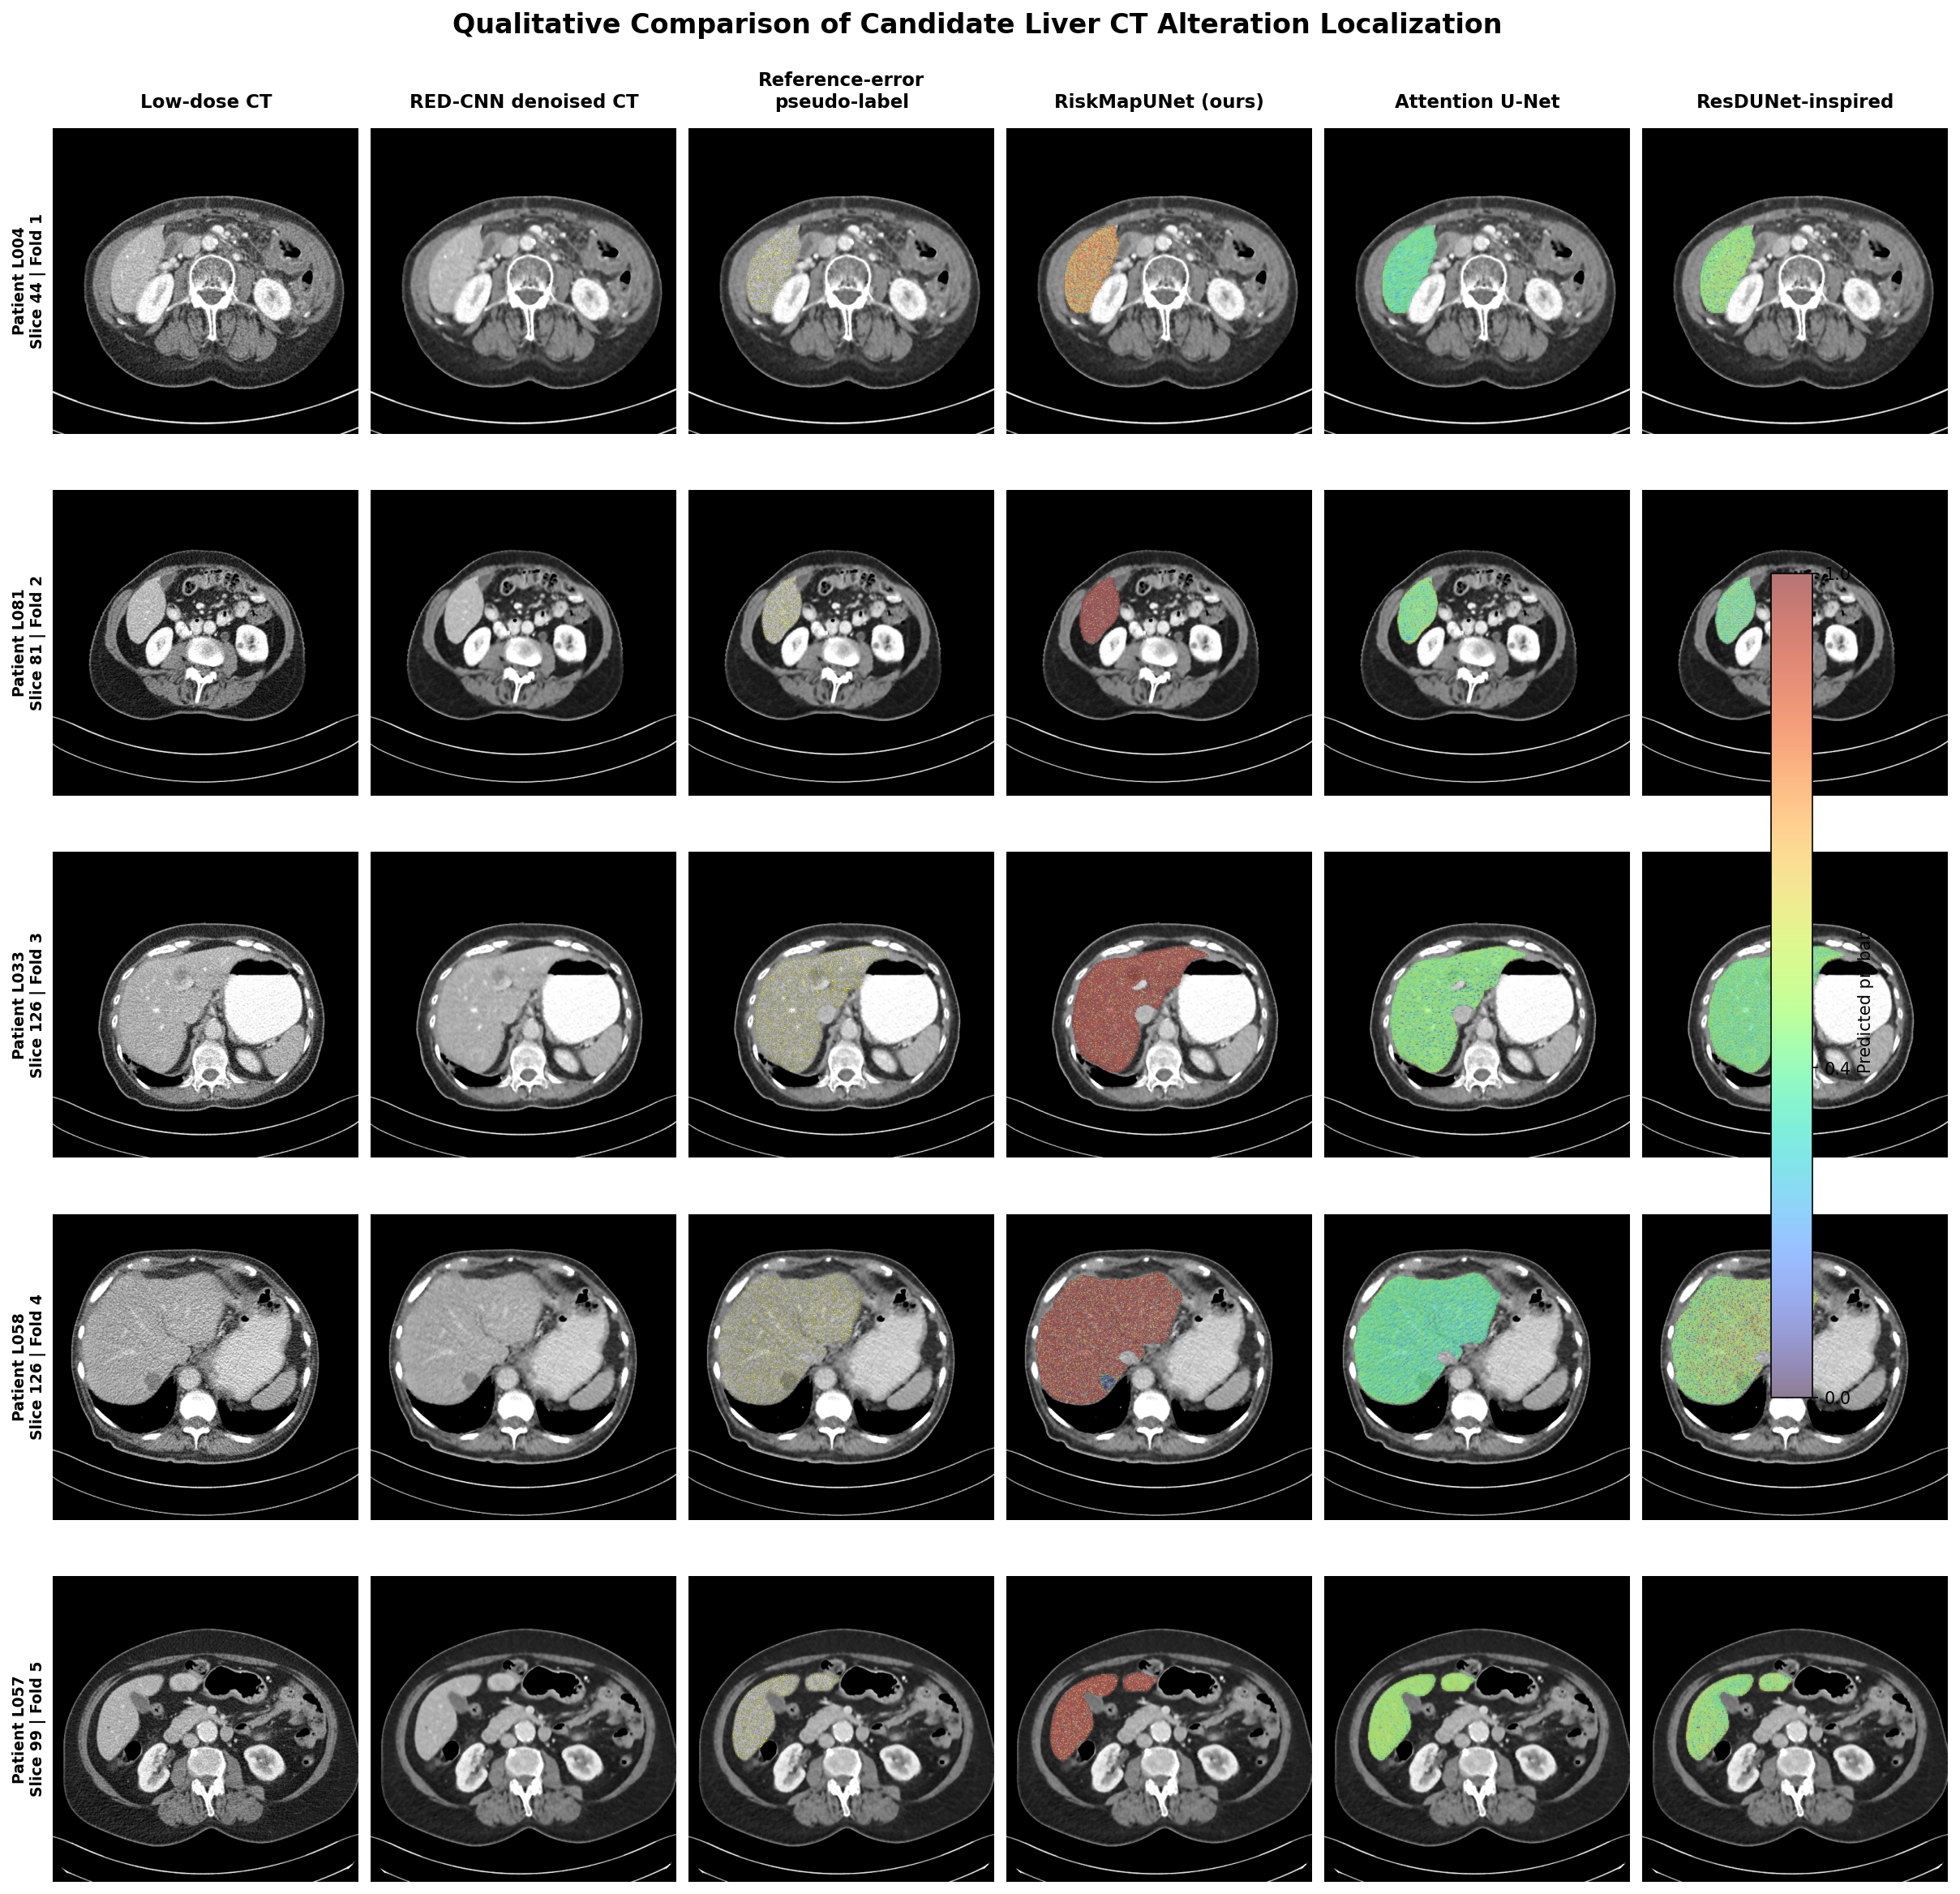

In [70]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/kaggle/working/CAI421_results/publication_figures")
OUT.mkdir(parents=True, exist_ok=True)

models = {
    "RiskMapUNet": {
        "class": lambda: RiskMapUNet(),
        "path": lambda f: Path(f"/kaggle/working/RiskMapUNet_v2_final/fold_{f}.pt")
    },
    "Attention U-Net": {
        "class": lambda: AttentionUNet(),
        "path": lambda f: Path(
            f"/kaggle/working/CAI421_results/baseline_attention_unet/"
            f"attention_unet_fold_{f}_best.pt"
        )
    },
    "ResDUNet": {
        "class": lambda: ResDUNetInspired(base=BASE_CHANNELS),
        "path": lambda f: Path(
            f"/kaggle/working/CAI421_results/baseline_resdunet_inspired/"
            f"resdunet_inspired_fold_{f}_best.pt"
        )
    }
}

# Choose one alteration-containing slice from each fold.
samples = []
for fold in range(1, 6):
    candidates = [
        r for r in records
        if r["fold"] == fold
        and np.any((r["y"] > 0.5) & (r["valid"] > 0))
    ]
    if not candidates:
        raise ValueError(f"No positive liver slice in fold {fold}")
    samples.append(candidates[0])

def load_model(name, fold):
    spec = models[name]
    path = spec["path"](fold)

    if not path.exists():
        raise FileNotFoundError(path)

    checkpoint = torch.load(
        path, map_location=DEVICE, weights_only=False
    )

    model = spec["class"]().to(DEVICE)

    state = checkpoint.get("model_state_dict", checkpoint) \
        if isinstance(checkpoint, dict) else checkpoint

    model.load_state_dict(state)
    model.eval()
    return model

def predict_sample(name, model, item):
    if name == "RiskMapUNet":
        # Use exactly the input construction from RiskMapUNet training.
        low = torch.as_tensor(
            item["x"][0][None], dtype=torch.float32, device=DEVICE
        )
        den = torch.as_tensor(
            item["x"][1][None], dtype=torch.float32, device=DEVICE
        )
        x = make_input(low, den)
    else:
        x = torch.as_tensor(
            item["x"][None], dtype=torch.float32, device=DEVICE
        )

    with torch.no_grad():
        prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()

    return np.where(item["valid"] > 0, prob, np.nan)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(5, 6, figsize=(19, 16), dpi=150)

titles = [
    "Low-dose CT",
    "RED-CNN denoised CT",
    "Reference-error\npseudo-label",
    "RiskMapUNet (ours)",
    "Attention U-Net",
    "ResDUNet-inspired"
]

for j, title in enumerate(titles):
    axes[0, j].set_title(title, fontweight="bold", pad=12)

for i, item in enumerate(samples):
    fold = item["fold"]
    low = item["x"][0]
    den = item["x"][1]
    truth = (item["y"] > 0.5) & (item["valid"] > 0)

    axes[i, 0].imshow(low, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].imshow(den, cmap="gray", vmin=0, vmax=1)

    axes[i, 2].imshow(den, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(
        np.ma.masked_where(~truth, truth),
        cmap="autumn", alpha=0.8, vmin=0, vmax=1
    )

    for j, name in enumerate(models, start=3):
        model = load_model(name, fold)
        prob = predict_sample(name, model, item)

        axes[i, j].imshow(den, cmap="gray", vmin=0, vmax=1)
        im = axes[i, j].imshow(
            np.ma.masked_invalid(prob),
            cmap="turbo", alpha=0.55, vmin=0, vmax=1
        )

        del model

    axes[i, 0].set_ylabel(
        f"Patient {item['case_id']}\n"
        f"Slice {item['slice']} | Fold {fold}",
        fontsize=9, fontweight="bold"
    )

    for ax in axes[i]:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

fig.colorbar(
    im, ax=axes[:, 3:].ravel().tolist(),
    shrink=0.55, pad=0.015, label="Predicted probability"
)

fig.suptitle(
    "Qualitative Comparison of Candidate Liver CT Alteration Localization",
    fontsize=16, fontweight="bold", y=0.995
)

fig.subplots_adjust(
    left=0.10, right=0.92, top=0.94,
    bottom=0.03, wspace=0.04, hspace=0.12
)

fig.savefig(OUT / "figure1_matched_heatmaps.png",
            dpi=300, bbox_inches="tight")
fig.savefig(OUT / "figure1_matched_heatmaps.pdf",
            bbox_inches="tight")
plt.show()

Dice, IoU, and AUC-PR grouped bar chart in which AUC-PR means 


Note: Precision: Of all pixels predicted as alterations, how many match the reference-error pseudo-label?
Recall: Of all reference-error pixels, how many did the model detect?

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/kaggle/working/CAI421_results/publication_figures")
OUT.mkdir(parents=True, exist_ok=True)

# Set these to the actual independent-test metric CSV files.
metric_files = {
    "RiskMapUNet": Path(
        "/kaggle/working/RiskMapUNet_v2_final/"
        "riskmap_5fold_test_metrics.csv"
    ),
    "Attention U-Net": Path(
        "/kaggle/working/CAI421_results/baseline_attention_unet/"
        "attention_unet_5fold_test_metrics.csv"
    ),
    "ResDUNet-inspired": Path(
        "/kaggle/working/CAI421_results/baseline_resdunet_inspired/"
        "resdunet_5fold_test_metrics.csv"
    )
}

metrics = ["dice", "iou", "auprc"]
rows = []

for name, path in metric_files.items():
    if not path.exists():
        raise FileNotFoundError(
            f"{name}: {path}\n"
            "Replace this path with the actual saved test-metrics CSV."
        )

    df = pd.read_csv(path)
    missing = set(metrics) - set(df.columns)

    if missing:
        raise ValueError(f"{name} missing metrics: {missing}")

    for metric in metrics:
        rows.append({
            "Model": name,
            "Metric": metric.upper() if metric != "auprc" else "AUC-PR",
            "Mean": df[metric].mean(),
            "SD": df[metric].std()
        })

plot_df = pd.DataFrame(rows)
plot_df.to_csv(OUT / "figure2_metrics.csv", index=False)

model_order = [
    "Attention U-Net",
    "ResDUNet-inspired",
    "RiskMapUNet"
]

metric_order = ["DICE", "IOU", "AUC-PR"]

colors = {
    "DICE": "#2B6CB0",
    "IOU": "#38A169",
    "AUC-PR": "#D69E2E"
}

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

x = np.arange(len(model_order))
width = 0.24

for i, metric in enumerate(metric_order):
    values = [
        plot_df.loc[
            (plot_df["Model"] == model) &
            (plot_df["Metric"] == metric),
            "Mean"
        ].iloc[0]
        for model in model_order
    ]

    errors = [
        plot_df.loc[
            (plot_df["Model"] == model) &
            (plot_df["Metric"] == metric),
            "SD"
        ].iloc[0]
        for model in model_order
    ]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        yerr=errors,
        capsize=4,
        label=metric,
        color=colors[metric],
        edgecolor="white",
        linewidth=0.8
    )

    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(model_order, fontsize=11)
ax.set_ylabel("Score", fontsize=11)
ax.set_ylim(0, 1.05)
ax.set_title(
    "Segmentation and Detection Performance Comparison",
    fontsize=14, fontweight="bold", pad=15
)
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(OUT / "figure2_metric_comparison.png",
            dpi=300, bbox_inches="tight")
fig.savefig(OUT / "figure2_metric_comparison.pdf",
            bbox_inches="tight")

plt.show()

display(plot_df.round(4))

FileNotFoundError: RiskMapUNet: /kaggle/working/RiskMapUNet_v2_final/riskmap_5fold_test_metrics.csv
Replace this path with the actual saved test-metrics CSV.

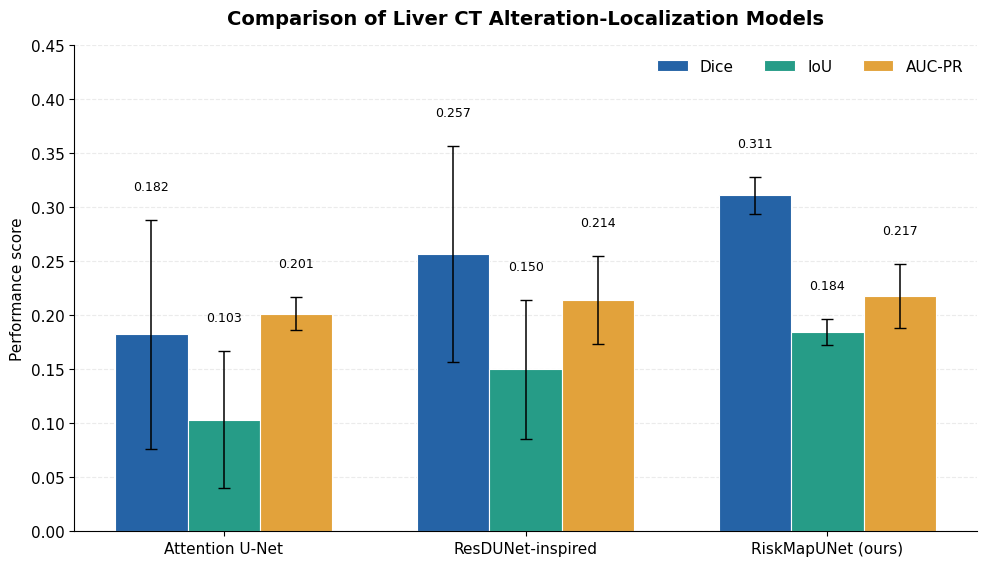

Metric,auprc,dice,iou
Model,,,
Attention U-Net,0.2014,0.1823,0.1032
ResDUNet-inspired,0.2140,0.2565,0.1501
RiskMapUNet (ours),0.2175,0.3109,0.1842


Saved to: /kaggle/working/CAI421_results/publication_figures


In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/kaggle/working/CAI421_results/publication_figures")
OUT.mkdir(parents=True, exist_ok=True)

metric_files = {
    "Attention U-Net": Path(
        "/kaggle/working/CAI421_results/baseline_attention_unet/"
        "attention_unet_5fold_metrics.csv"
    ),
    "ResDUNet-inspired": Path(
        "/kaggle/working/CAI421_results/baseline_resdunet_inspired/"
        "resdunet_5fold_test_metrics.csv"
    ),
    "RiskMapUNet (ours)": Path(
        "/kaggle/working/RiskMapUNet_v2_final/"
        "five_fold_results.csv"
    )
}

metrics = ["dice", "iou", "auprc"]
rows = []

for model, path in metric_files.items():
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.lower()

    if "auprc" not in df.columns and "auc_pr" in df.columns:
        df = df.rename(columns={"auc_pr": "auprc"})

    missing = set(metrics) - set(df.columns)
    if missing:
        raise ValueError(
            f"{model}: missing {missing}\n"
            f"Available columns: {list(df.columns)}"
        )

    for metric in metrics:
        values = pd.to_numeric(df[metric], errors="coerce").dropna()

        if len(values) != 5:
            raise ValueError(
                f"{model}: expected 5 fold values for {metric}, "
                f"found {len(values)}"
            )

        rows.append({
            "Model": model,
            "Metric": metric,
            "Mean": values.mean(),
            "SD": values.std(ddof=1)
        })

plot_df = pd.DataFrame(rows)
plot_df.to_csv(OUT / "figure2_metrics.csv", index=False)

models = list(metric_files.keys())
metric_labels = {
    "dice": "Dice",
    "iou": "IoU",
    "auprc": "AUC-PR"
}
colors = {
    "dice": "#2563A6",
    "iou": "#269C87",
    "auprc": "#E2A23B"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(10, 5.8))

x = np.arange(len(models))
width = 0.24

for i, metric in enumerate(metrics):
    subset = (
        plot_df[plot_df["Metric"] == metric]
        .set_index("Model")
        .loc[models]
    )

    means = subset["Mean"].to_numpy()
    stds = subset["SD"].to_numpy()

    bars = ax.bar(
        x + (i - 1) * width,
        means,
        width,
        yerr=stds,
        capsize=4,
        color=colors[metric],
        label=metric_labels[metric],
        edgecolor="white",
        linewidth=0.8,
        error_kw={"elinewidth": 1.1}
    )

    for bar, value, sd in zip(bars, means, stds):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            min(value + sd + 0.025, 1.07),
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel("Performance score")
ax.set_ylim(0, 0.45)
ax.set_title(
    "Comparison of Liver CT Alteration-Localization Models",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.legend(frameon=False, ncol=3, loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    OUT / "figure2_dice_iou_auprc.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    OUT / "figure2_dice_iou_auprc.pdf",
    bbox_inches="tight"
)

plt.show()

display(
    plot_df.pivot(
        index="Model",
        columns="Metric",
        values="Mean"
    ).round(4)
)

print("Saved to:", OUT)

1. RiskMapUNet achieves the highest Dice and IoU meaning it has better masking overlap
2. RiskMapUNet's AUC-PR is only 0.2175-0.2140= 0.0035 higher than ResDUNet yet it still indicates that its ability to rank altered pixels is quite similiar
3. Attention U-Net and ResDUNet-inspired have relatively large error bars for Dice and IoU meanwhile, RiskMapUNet appears more consistent across the five folds.
in conclusion, riskmapUnet is  powerful than ResDUNet by minor significance
**Research question:** Can RiskMapUNet accurately localize regions where RED-CNN denoising increases reference error within the liver?
> this research was conducted to evaluate how RED-CNN denoising affects the visibility of liver abnormalities, such as cysts and lesions, in low-dose CT scans. Our main novelty lies in the benchmarking and evaluation, comparing RiskMapUNet with established U-Net baselines to assess how effectively they localize candidate image alterations.